# Nighthawk Qrack (`nighthawk_qrack.py`) — Google Colab Setup & Verification

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/twobombs/thereminq-examples/blob/main/devices/nighthawk-r3/nighthawk_qrack_colab.ipynb)

This notebook sets up and verifies [`nighthawk_qrack.py`](https://github.com/twobombs/thereminq-examples/blob/main/devices/nighthawk-r3/nighthawk_qrack.py), the consolidated clean-qubit **PyQrack** companion to `arXiv:2609.28657` (random-circuit sampling on IBM Nighthawk r2 / `ibm_phoenix`, 61 qubits) and IBM Nighthawk r3 / multi-chip cloverfield simulations.

### Workflow
1. **Install dependencies** (`pyqrack`, `qiskit`, `ortools`, `scipy`, `matplotlib`, `numpy`, and OpenCL via NVIDIA ICD on GPU runtimes or `pocl-opencl-icd` on CPU runtimes).
2. **Clone repositories** (`twobombs/thereminq-examples` and `BlueQubitDev/rcs-nighthawk`).
3. **Verify circuits & release data** (`verify` and `seamgap`).
4. **Run the self-test suites** (`selftest`, `ghz selftest`, `field selftest`, `erepr selftest`, `lab --selftest`).
5. **Inspect Nighthawk r3 device plans** (`field plan --device r3x2s`, `r3x2`, `clover6`).

## 1. Environment & Dependency Setup

Run the cell below to install Python packages (`pyqrack`, `qiskit`, `ortools`, `scipy`, `matplotlib`) and configure OpenCL (NVIDIA OpenCL ICD when a GPU is detected, or `pocl-opencl-icd` when running on CPU).

In [1]:
import os
import shutil
import subprocess
import sys

# Install required Python packages
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "pyqrack", "qiskit", "ortools", "scipy", "matplotlib", "numpy"
])

# Check for GPU via nvidia-smi; if no GPU is detected, install PoCL (pocl-opencl-icd)
has_nvidia = shutil.which("nvidia-smi") is not None and subprocess.call(
    ["nvidia-smi"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL
) == 0

subprocess.check_call(["apt-get", "update", "-qq"])
if has_nvidia:
    print("GPU detected via nvidia-smi; configuring NVIDIA OpenCL ICD...")
    subprocess.check_call(["apt-get", "install", "-y", "-qq", "ocl-icd-libopencl1", "clinfo"])
    os.makedirs("/etc/OpenCL/vendors", exist_ok=True)
    nv_icd = "/etc/OpenCL/vendors/nvidia.icd"
    if not os.path.exists(nv_icd):
        with open(nv_icd, "w") as f:
            f.write("libnvidia-opencl.so.1\n")
else:
    print("No GPU detected; installing PoCL (pocl-opencl-icd) for CPU OpenCL support...")
    subprocess.check_call(["apt-get", "install", "-y", "-qq", "pocl-opencl-icd", "ocl-icd-libopencl1", "clinfo"])

print("\nOpenCL devices (clinfo -l):")
subprocess.call(["clinfo", "-l"])

import pyqrack
from importlib.metadata import version
print(f"\nPyQrack version: {version('pyqrack')}")
print(f"Qiskit version:  {version('qiskit')}")
print(f"OR-Tools version: {version('ortools')}")

No GPU detected; installing PoCL (pocl-opencl-icd) for CPU OpenCL support...

OpenCL devices (clinfo -l):
Platform #0: pthread-cpu
 `-- Device #0: cpu

PyQrack version: 2.30.6
Qiskit version:  2.6.2
OR-Tools version: 9.15.6755


## 2. Clone Repositories & Set Working Directory

This cell clones `twobombs/thereminq-examples` (if not already present), moves into `devices/nighthawk-r3`, and clones the `BlueQubitDev/rcs-nighthawk` dataset next to `nighthawk_qrack.py`.

In [2]:
from pathlib import Path

if not Path("nighthawk_qrack.py").is_file():
    if not Path("thereminq-examples").is_dir():
        !git clone --depth 1 https://github.com/twobombs/thereminq-examples.git
    %cd thereminq-examples/devices/nighthawk-r3

if not Path("rcs-nighthawk/data/layout.json").is_file():
    !git clone --depth 1 https://github.com/BlueQubitDev/rcs-nighthawk.git rcs-nighthawk

os.environ["NIGHTHAWK_REPO"] = str(Path("rcs-nighthawk").resolve())
print("Working directory:", Path.cwd())
print("NIGHTHAWK_REPO:   ", os.environ["NIGHTHAWK_REPO"])

Working directory: /content/thereminq-examples/devices/nighthawk-r3
NIGHTHAWK_REPO:    /content/thereminq-examples/devices/nighthawk-r3/rcs-nighthawk


## 3. Circuit & Release Data Verification (`verify` & `seamgap`)

- `verify` regenerates all 233 circuits from `data/layout.json` and checks them gate-for-gate against `data/circuits/*.qasm`.
- `seamgap` runs the data-only analysis of CZ counts and fidelity vs. depth fits on the released dataset.

In [3]:
!python3 nighthawk_qrack.py verify --repo rcs-nighthawk
!python3 nighthawk_qrack.py seamgap --repo rcs-nighthawk

232 identical, 0 different (angle tol 1e-09 rad)
== CZ counts (mean [min-max]); gaps relative to the sampled full circuit ==
depth	full	mirror	K3	K4	full-mirror	full-K3
4	102[102-102]	94[94-94]	-	-	8 (7.8%)	-
6	-	150[150-150]	-	-	-	-
8	204[204-204]	190[190-190]	-	-	14 (6.9%)	-
10	-	232[232-232]	-	-	-	-
12	306[306-306]	264[264-264]	-	-	42 (13.7%)	-
14	-	312[312-312]	-	-	-	-
16	408[408-408]	348[348-348]	-	-	60 (14.7%)	-
18	-	398[398-398]	-	-	-	-
20	510[510-510]	442[442-442]	444[440-450]	401[395-415]	68 (13.3%)	66 (12.9%)
24	612[612-612]	532[532-532]	533[528-540]	481[474-498]	80 (13.1%)	79 (12.9%)
28	714[714-714]	616[616-616]	622[616-630]	561[553-581]	98 (13.7%)	92 (12.9%)
32	816[816-816]	706[706-706]	710[704-720]	642[632-664]	110 (13.5%)	106 (12.9%)
36	918[918-918]	802[802-802]	799[792-810]	722[711-747]	116 (12.6%)	119 (12.9%)
40	1020[1020-1020]	888[888-888]	888[880-900]	802[790-830]	132 (12.9%)	132 (12.9%)

== fit F(d) = 0.3257 x 0.8717^d ==
at d=36: 2.321e-03 (headline);  at gate-count

## 4. Self-Test Suites

Run the built-in self-tests across all command groups to confirm exactness, angle conventions, Pauli twirling, XEB scoring, CP-SAT layout search, VQE, Shor-9, QrackBridge, GHZ, Cloverfield loom, ER=EPR, and the Configuration Lab.

In [4]:
# Main self-test suite (14 checks: circuit regeneration, Haar u_angles, exact mirror, Pauli twirl,
# ideal patch XEB, hardware counts XEB, ACE mapping, register recipe, CP-SAT layoutsearch,
# nnqab gate inverses, TFIM VQE, Shor-9, and horizontal QrackBridge)
!python3 nighthawk_qrack.py selftest --repo rcs-nighthawk

[1] angle hash + pseudo-patch rotation vs released mirror/d08_instance1.qasm: identical  OK
[2] u_angles -> Qrack u == Haar matrix: overlap 1.0000000  OK
# progress n14 mirror d12 i0: circuit run 1/10, 10.0% of cycles, elapsed 0m00s, ETA 0m00s
[3] exact mirror, first 14 logical qubits, d=12, 10 inputs: F = 0.9999999  OK
[4] Pauli-frame twirl is an identity (exact): F = 0.9999999  OK
[5] PyQrack patch ideal XEB vs release (Aer, double): max diff 1.8e-08  OK
[6] Eq.(1)-(2) on the hardware counts vs release: 0.02555 vs 0.02555 (se 3.9e-03)  OK
[7] ideal samples score F = 1 within 4 se: F = 0.9582 +/- 0.0380  OK
[8] ACE register 64 qubits, grid 8x8, is_torus=False; logical->ACE map is nearest-neighbour for all couplers: True
[9] --register recipe reproduces the release's inputs and K = 3, 4 partitions: identical  OK
[10] layoutsearch joint model vs exact engine, release register on 75 sites (lrc 4 lrr 5, torus): 8 / 8 boundary qubits, 26 / 29 couplers through a boundary  OK
# progress n14 

In [5]:
# Subgroup self-tests: ghz, field, erepr, and lab
!python3 nighthawk_qrack.py ghz selftest
!python3 nighthawk_qrack.py field selftest
!python3 nighthawk_qrack.py erepr selftest
!python3 nighthawk_qrack.py lab --selftest

[1] Lemma 4 (MQC) and the witness against numpy density matrices (k = 3, 4, 5)
  [ok] k=3 theta=0.0 flip=0.0 dephase=0.0: c +0.5000+0.0000i / +0.5000+0.0000i, F_GHZ 1.0000 / max_theta 1.0000, F0 1.0000 / 1.0000, witness 1.0000
  [ok] k=3 theta=0.7 flip=0.0 dephase=0.0: c +0.3824-0.3221i / +0.3824-0.3221i, F_GHZ 1.0000 / max_theta 1.0000, F0 0.8824 / 0.8824, witness 0.8824
  [ok] k=3 theta=0.0 flip=0.1 dephase=0.0: c +0.4500+0.0000i / +0.4500+0.0000i, F_GHZ 0.9000 / max_theta 0.9000, F0 0.9000 / 0.9000, witness 0.9000
  [ok] k=3 theta=0.3 flip=0.05 dephase=0.4: c +0.2723-0.0842i / +0.2723-0.0842i, F_GHZ 0.7600 / max_theta 0.7600, F0 0.7473 / 0.7473, witness 0.7366
  [ok] k=4 theta=0.0 flip=0.0 dephase=0.0: c +0.5000+0.0000i / +0.5000+0.0000i, F_GHZ 1.0000 / max_theta 1.0000, F0 1.0000 / 1.0000, witness 1.0000
  [ok] k=4 theta=0.7 flip=0.0 dephase=0.0: c +0.3824-0.3221i / +0.3824-0.3221i, F_GHZ 1.0000 / max_theta 1.0000, F0 0.8824 / 0.8824, witness 0.8824
  [ok] k=4 theta=0.0 flip=0.1 de

## 5. Nighthawk r3 & Cloverfield Plans and Quick Run

Inspect the multi-chip Nighthawk r3 device presets (`r3x2s`, `r3x2`, `clover6`) and run a quick mirror/Hamming circuit test.

cloverfield: 2 chips ['nighthawk520', 'nighthawk520'] on a 1 x 2 grid, 1040 qubits
device r3x2: the system IBM plans for 2027: two Nighthawk r3 chips, 1,040 qubits, ten l-couplers; about 500 CZs per cycle, so the device's 10000 two-qubit gates are about 20 cycles of this field
colour   intra-chip CZ   link CZ
  A           520           0
  B           480          10
  C           520           0
  D           468           0
links: 10, loom ghost
  chip 0 site (0, 25) -- chip 1 site (0, 0)  colour B
  chip 0 site (2, 25) -- chip 1 site (2, 0)  colour B
  chip 0 site (4, 25) -- chip 1 site (4, 0)  colour B
  chip 0 site (6, 25) -- chip 1 site (6, 0)  colour B
  chip 0 site (8, 25) -- chip 1 site (8, 0)  colour B
  chip 0 site (11, 25) -- chip 1 site (11, 0)  colour B
  chip 0 site (13, 25) -- chip 1 site (13, 0)  colour B
  chip 0 site (15, 25) -- chip 1 site (15, 0)  colour B
  chip 0 site (17, 25) -- chip 1 site (17, 0)  colour B
  chip 0 site (19, 25) -- chip 1 site (19, 0)  colour

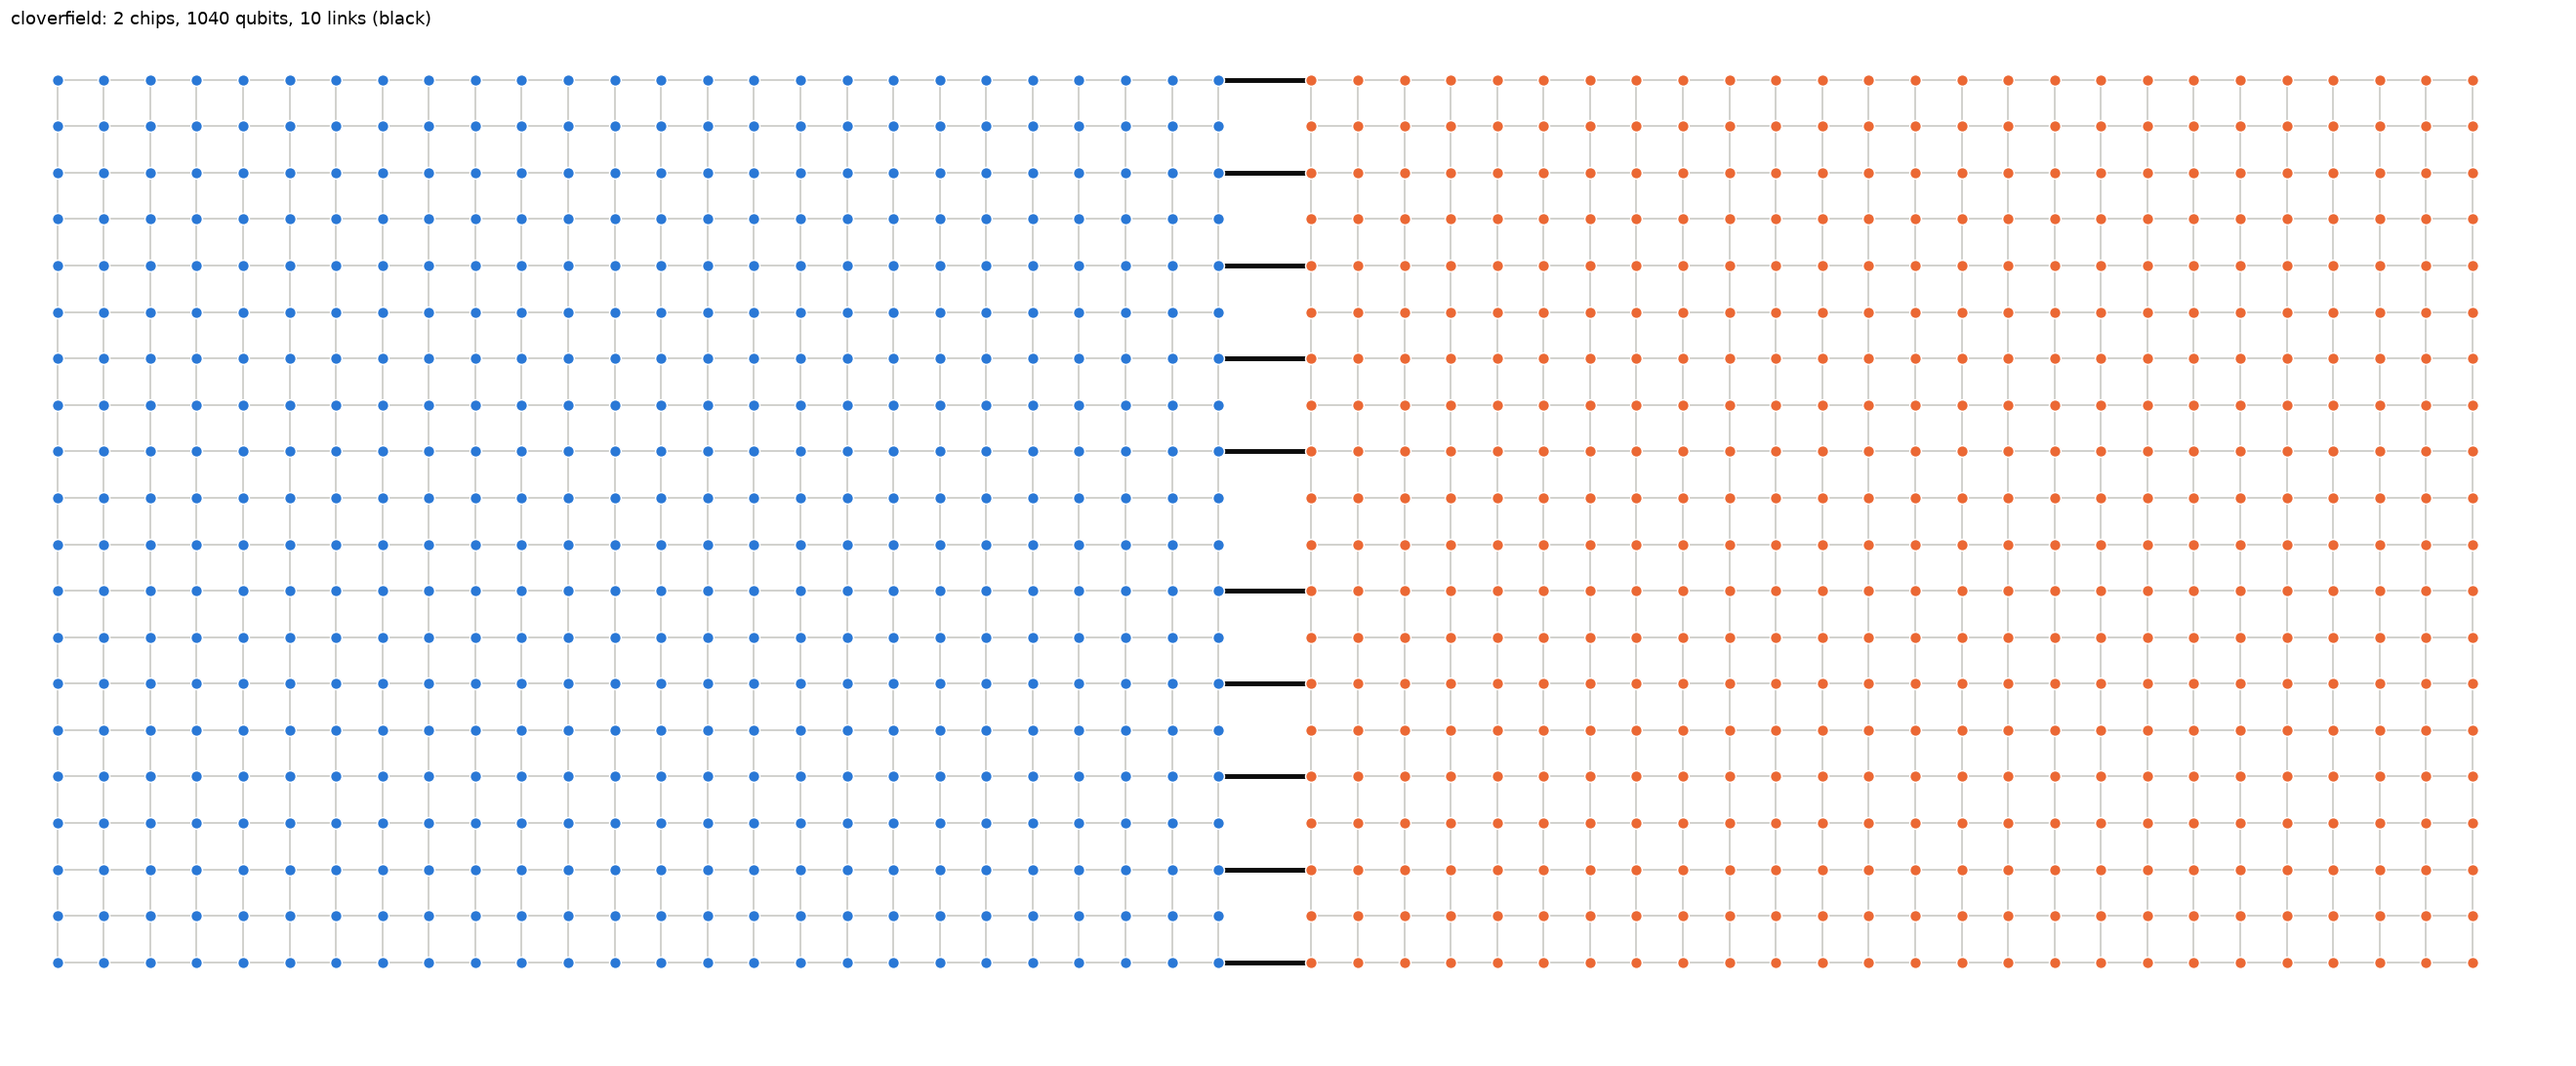

cloverfield: 2 chips ['nighthawk120', 'nighthawk120'] on a 1 x 2 grid, 240 qubits
device r3x2s: r3x2 scaled to what runs here: the same two chips and ten l-couplers on 120-qubit chips; about 112 CZs per cycle, so the device's 10000 two-qubit gates are about 89 cycles of this field
colour   intra-chip CZ   link CZ
  A           120           0
  B            96          10
  C           120           0
  D           100           0
links: 10, loom ghost
  chip 0 site (0, 9) -- chip 1 site (0, 0)  colour B
  chip 0 site (1, 9) -- chip 1 site (1, 0)  colour B
  chip 0 site (2, 9) -- chip 1 site (2, 0)  colour B
  chip 0 site (4, 9) -- chip 1 site (4, 0)  colour B
  chip 0 site (5, 9) -- chip 1 site (5, 0)  colour B
  chip 0 site (6, 9) -- chip 1 site (6, 0)  colour B
  chip 0 site (7, 9) -- chip 1 site (7, 0)  colour B
  chip 0 site (9, 9) -- chip 1 site (9, 0)  colour B
  chip 0 site (10, 9) -- chip 1 site (10, 0)  colour B
  chip 0 site (11, 9) -- chip 1 site (11, 0)  colour B
topology 

In [6]:
from IPython.display import Image, display

# Plan the 1,040-qubit two-chip Nighthawk r3 system and render its layout diagram
!python3 nighthawk_qrack.py field plan --device r3x2 --backend exact --png r3x2.png
if Path("r3x2.png").is_file():
    display(Image("r3x2.png"))

# Plan the 240-qubit scaled two-chip r3x2s field on the ghost loom
!python3 nighthawk_qrack.py field plan --device r3x2s --loom ghost

In [7]:
# List distinct ACE layouts of the 61-qubit register up to max simulator width 28
!python3 nighthawk_qrack.py aceplan --repo rcs-nighthawk --max-width 28

ACE layouts of the 8x8 register (64 sites) holding the first 61 logical qubits (102 circuit couplers); 8 bytes/amplitude; ranked by couplers across simulators, device-grid placement
torus  lrc lrr  cross CZ  seam CZ  seam qb  sims  widest  dense GB (worst)  simulator widths
False    4   2        31       74       22     7      23               0.1  [23, 23, 19, 15, 14, 14, 11]  <- pick
False    6   2        31       75       22     7      23               0.1  [23, 23, 21, 16, 13, 12, 11]
False    5   2        32       74       22     7      23               0.1  [23, 22, 21, 15, 14, 13, 11]
False    4   6        37       70       15     5      23               0.1  [23, 23, 20, 19, 16]
False    6   6        37       71       15     5      25               0.3  [25, 21, 20, 19, 16]
False    4   5        38       69       15     5      23               0.1  [23, 23, 20, 19, 16]
False    5   6        38       70       15     5      24               0.2  [24, 22, 20, 19, 16]
False    6   

## 6. Execute `nighthawk_graph.py` on Measured Results

Generate summary tables, multi-chip Cloverfield topology posters (`r3_topo.jsonl`), and RCS / Mirror / FXEB / Hamming figures (`../nighthawk/rcs-nighthawk/nighthawk.tar.gz`) using [`nighthawk_graph.py`](https://github.com/twobombs/thereminq-examples/blob/main/devices/nighthawk-r3/nighthawk_graph.py).

### 6.1 Cloverfield (`clover6`, 720 Qubits) Measured Topologies (`r3_topo.jsonl`)

Plot the measured 720-qubit Cloverfield records across `ring`, `hub 1`, and `grid + 0-5,2-3` topologies (view 29, Hamming views 12–13, and one-page topology posters).

field-093ed631: 4 points, field-25da32df: 4 points, field-52dcd722: 4 points, field-650ca988: 4 points, field-6edd8b39: 4 points, field-9128f452: 4 points; hwxeb circuits: 0; shor9 records: 0; ghz records: 0; shor_bridge records: 0; dual_r1 rows: 0; dual_map chains: 0; shor_alg circuits: 0; read 09:07:35
wrote 24 points of 6 configurations to /tmp/nh_plots/r3_topo.csv
field-093ed631: 4 points, field-25da32df: 4 points, field-52dcd722: 4 points, field-650ca988: 4 points, field-6edd8b39: 4 points, field-9128f452: 4 points; hwxeb circuits: 0; shor9 records: 0; ghz records: 0; shor_bridge records: 0; dual_r1 rows: 0; dual_map chains: 0; shor_alg circuits: 0; read 09:07:36
saved /tmp/nh_plots/12_hm.png
saved /tmp/nh_plots/13_hmr.png
saved /tmp/nh_plots/29_fld.png
field-093ed631: 4 points, field-25da32df: 4 points, field-52dcd722: 4 points, field-650ca988: 4 points, field-6edd8b39: 4 points, field-9128f452: 4 points; hwxeb circuits: 0; shor9 records: 0; ghz records: 0; shor_bridge records: 0

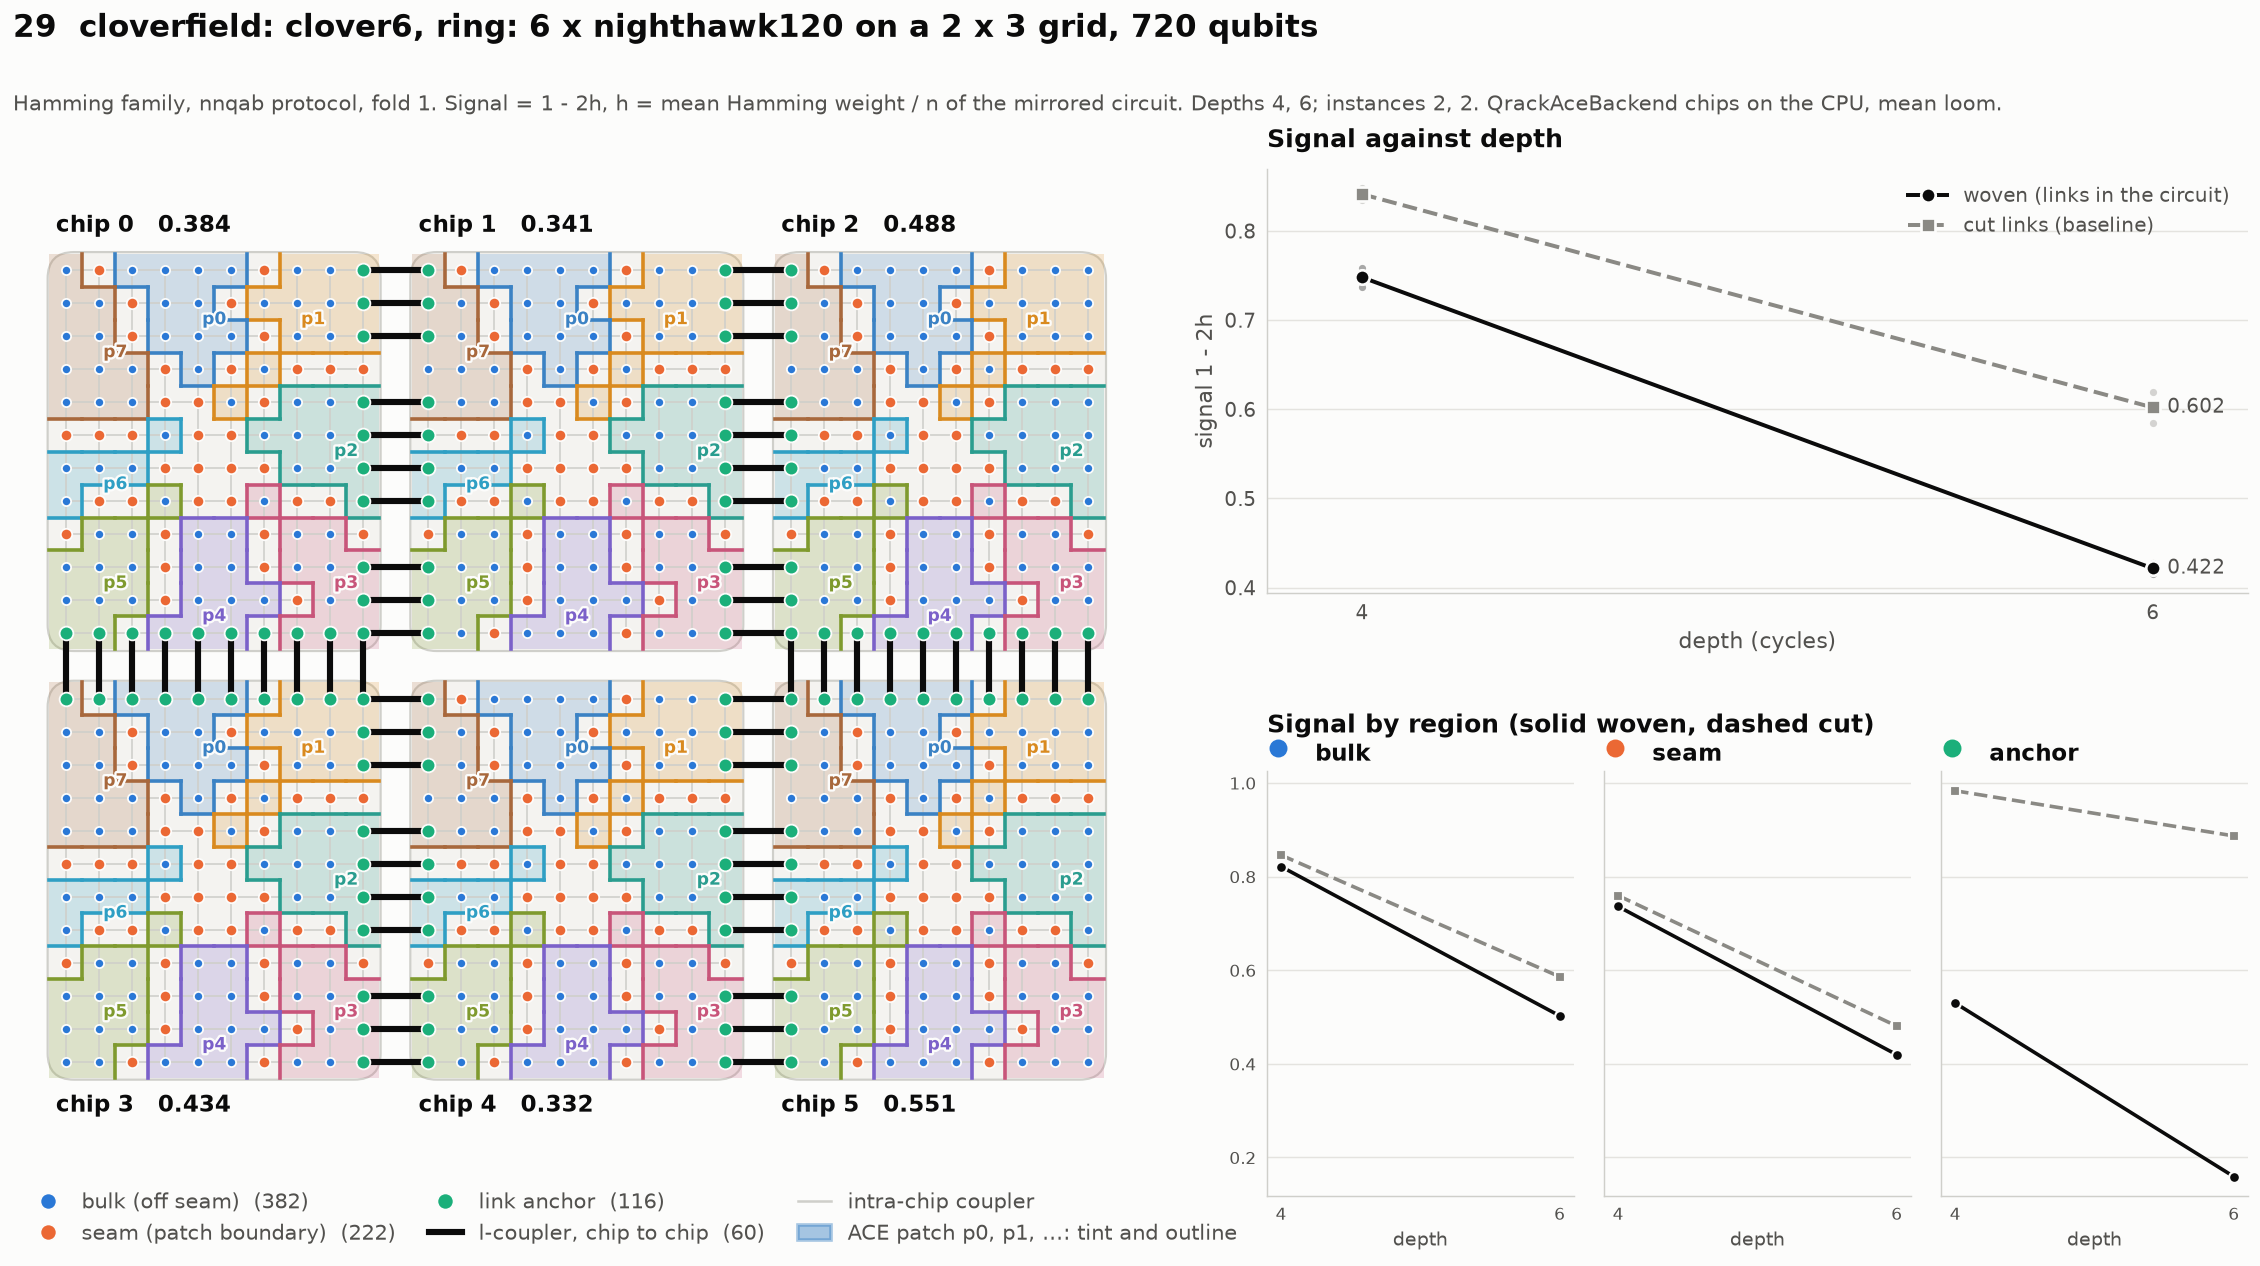

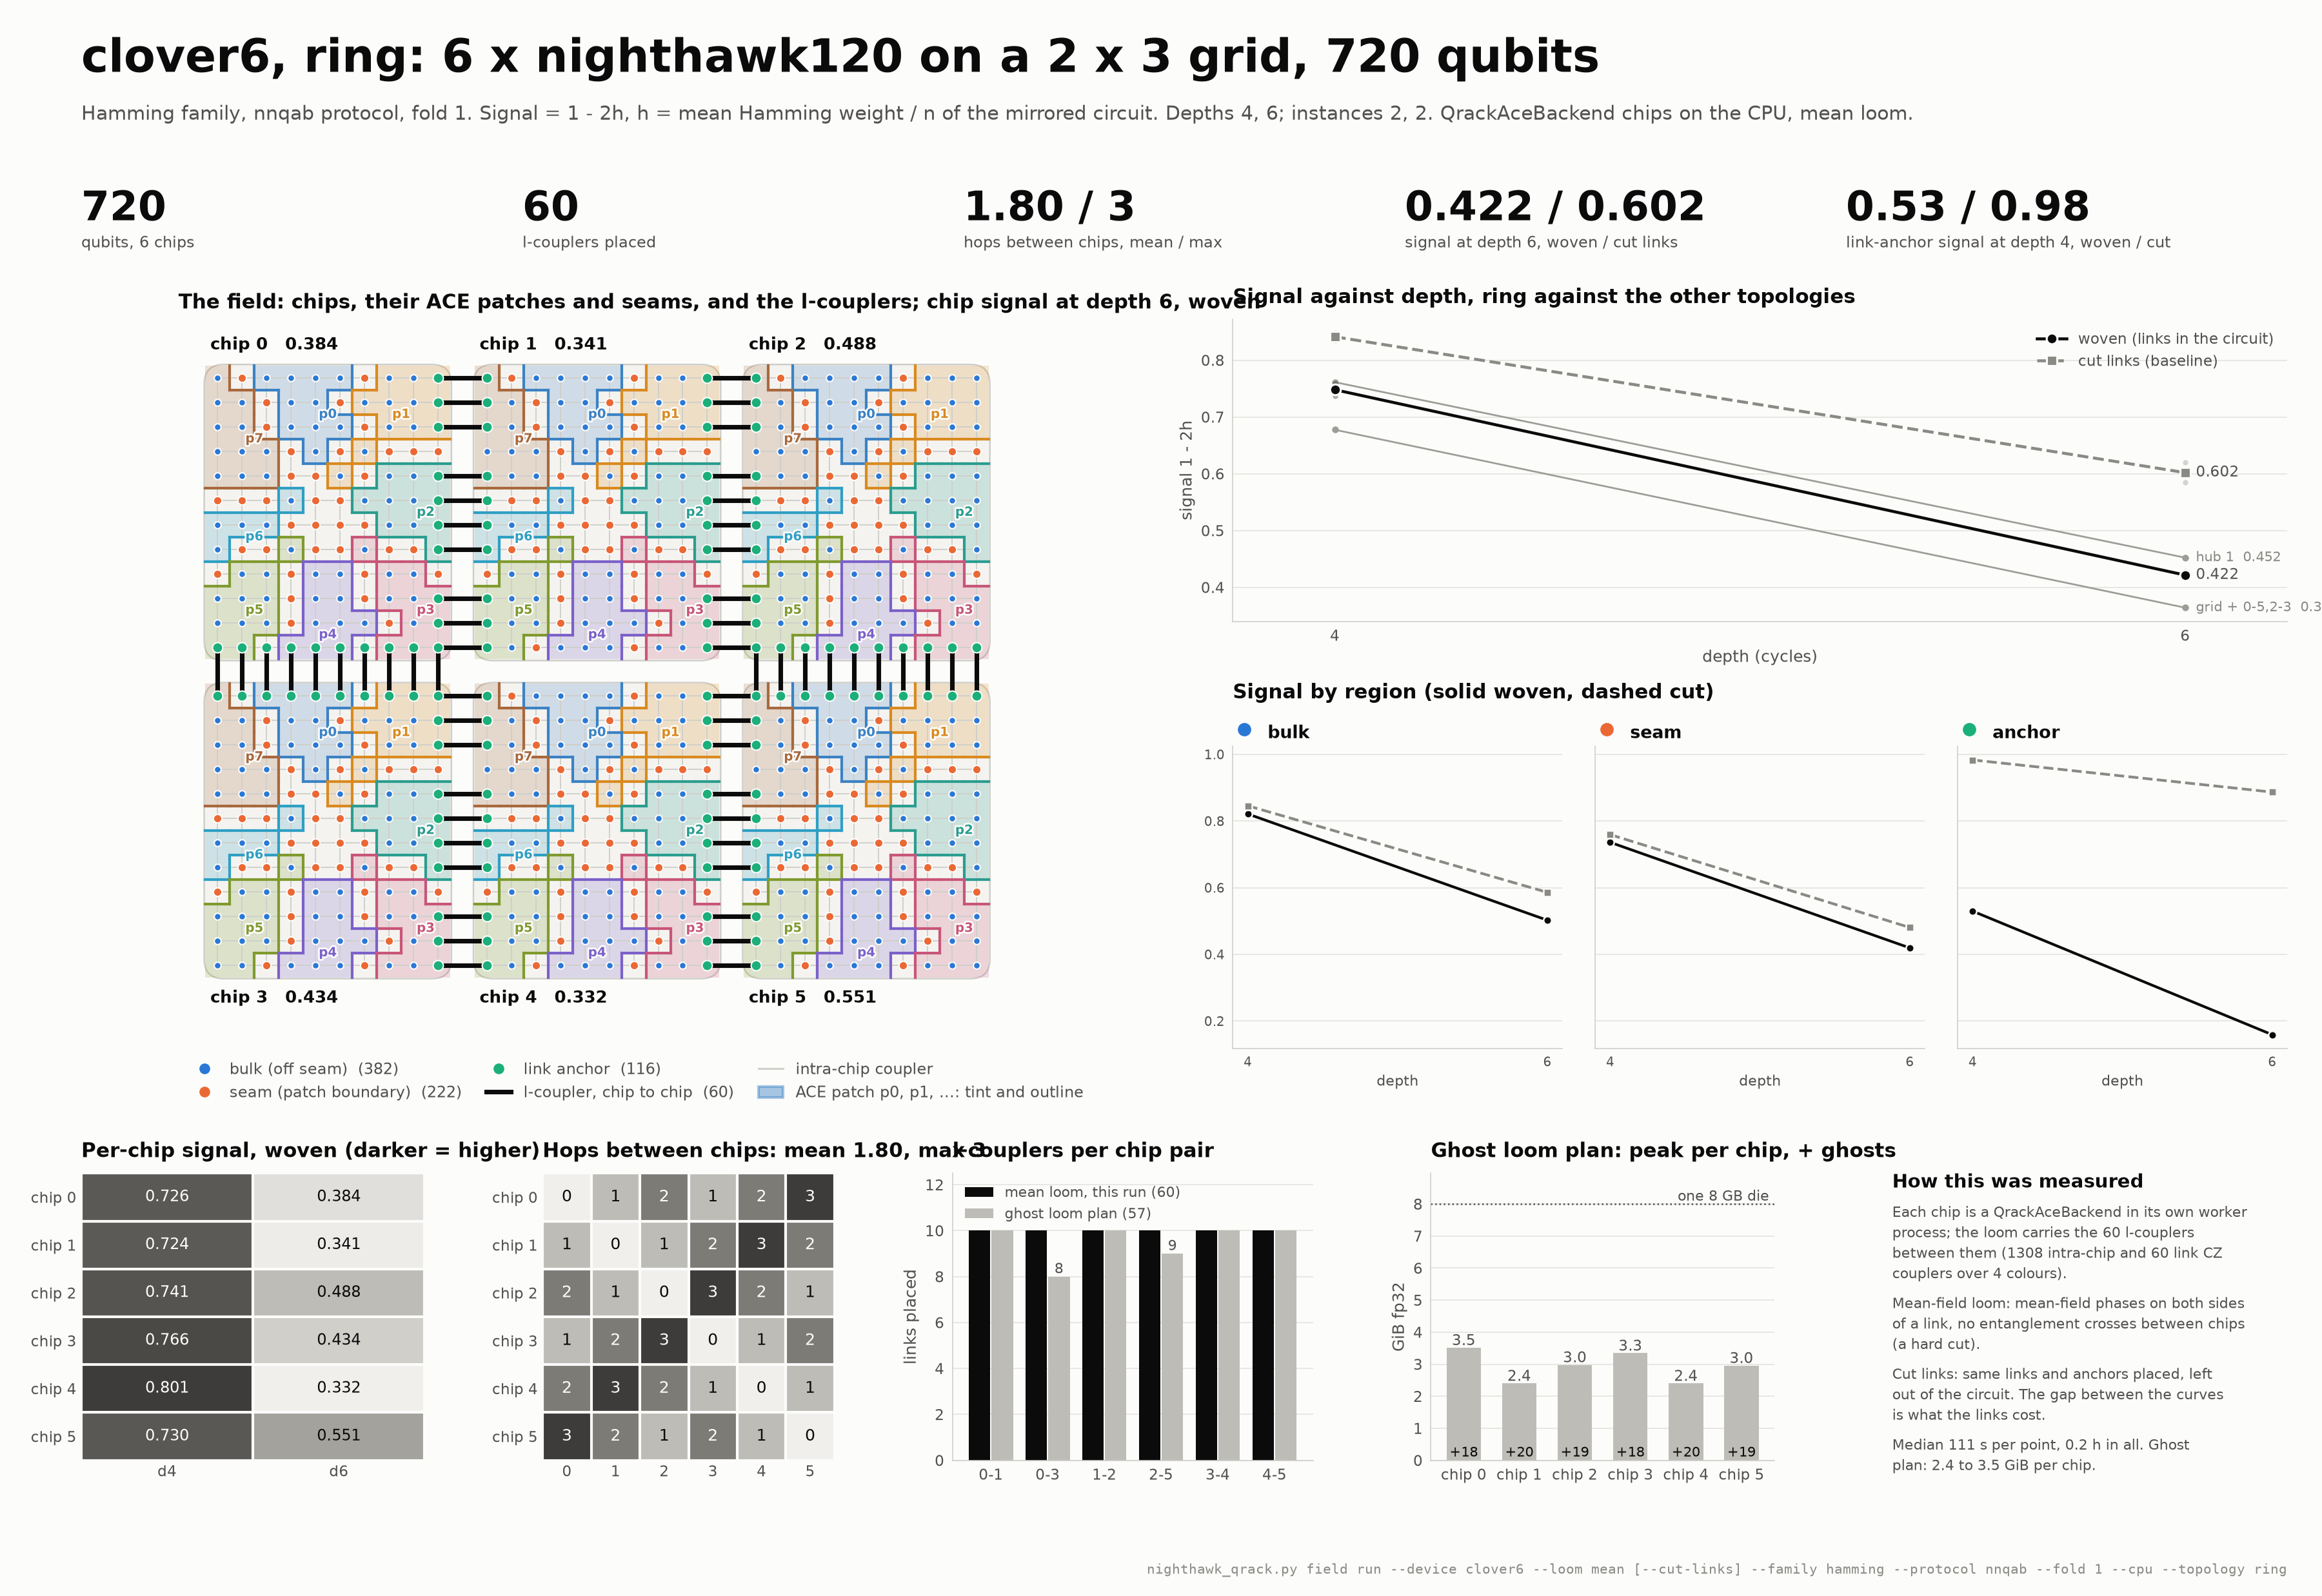

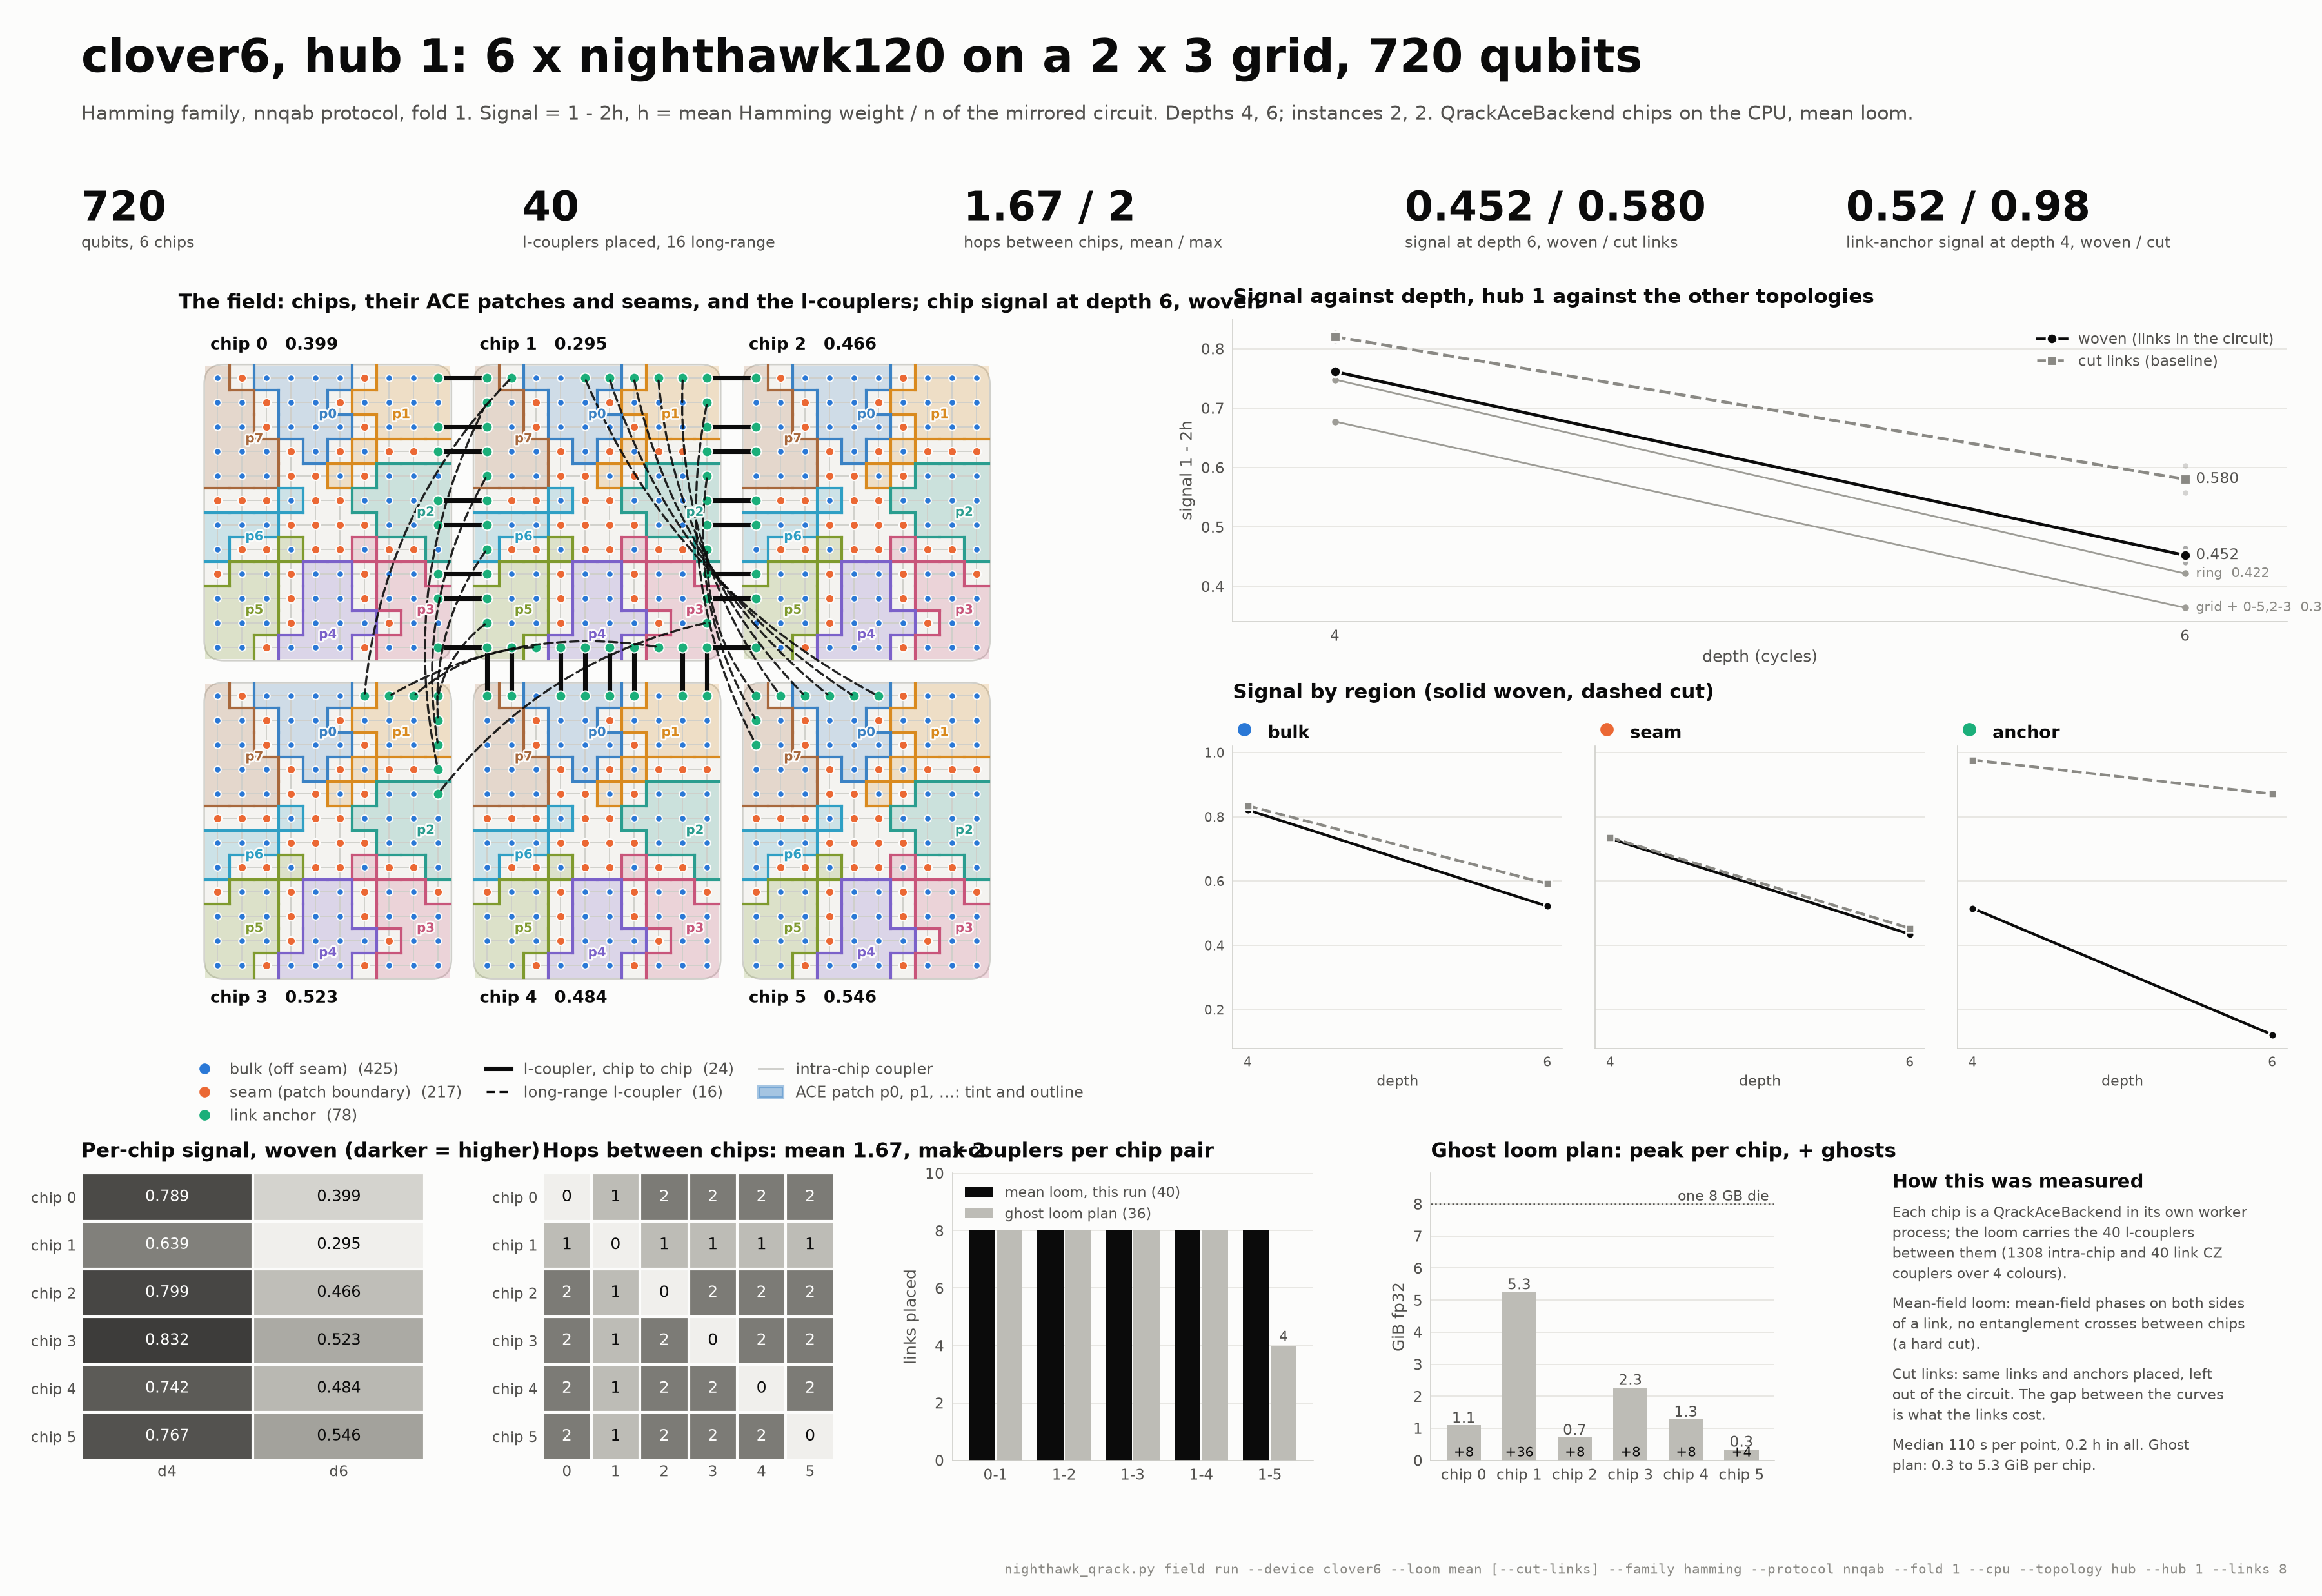

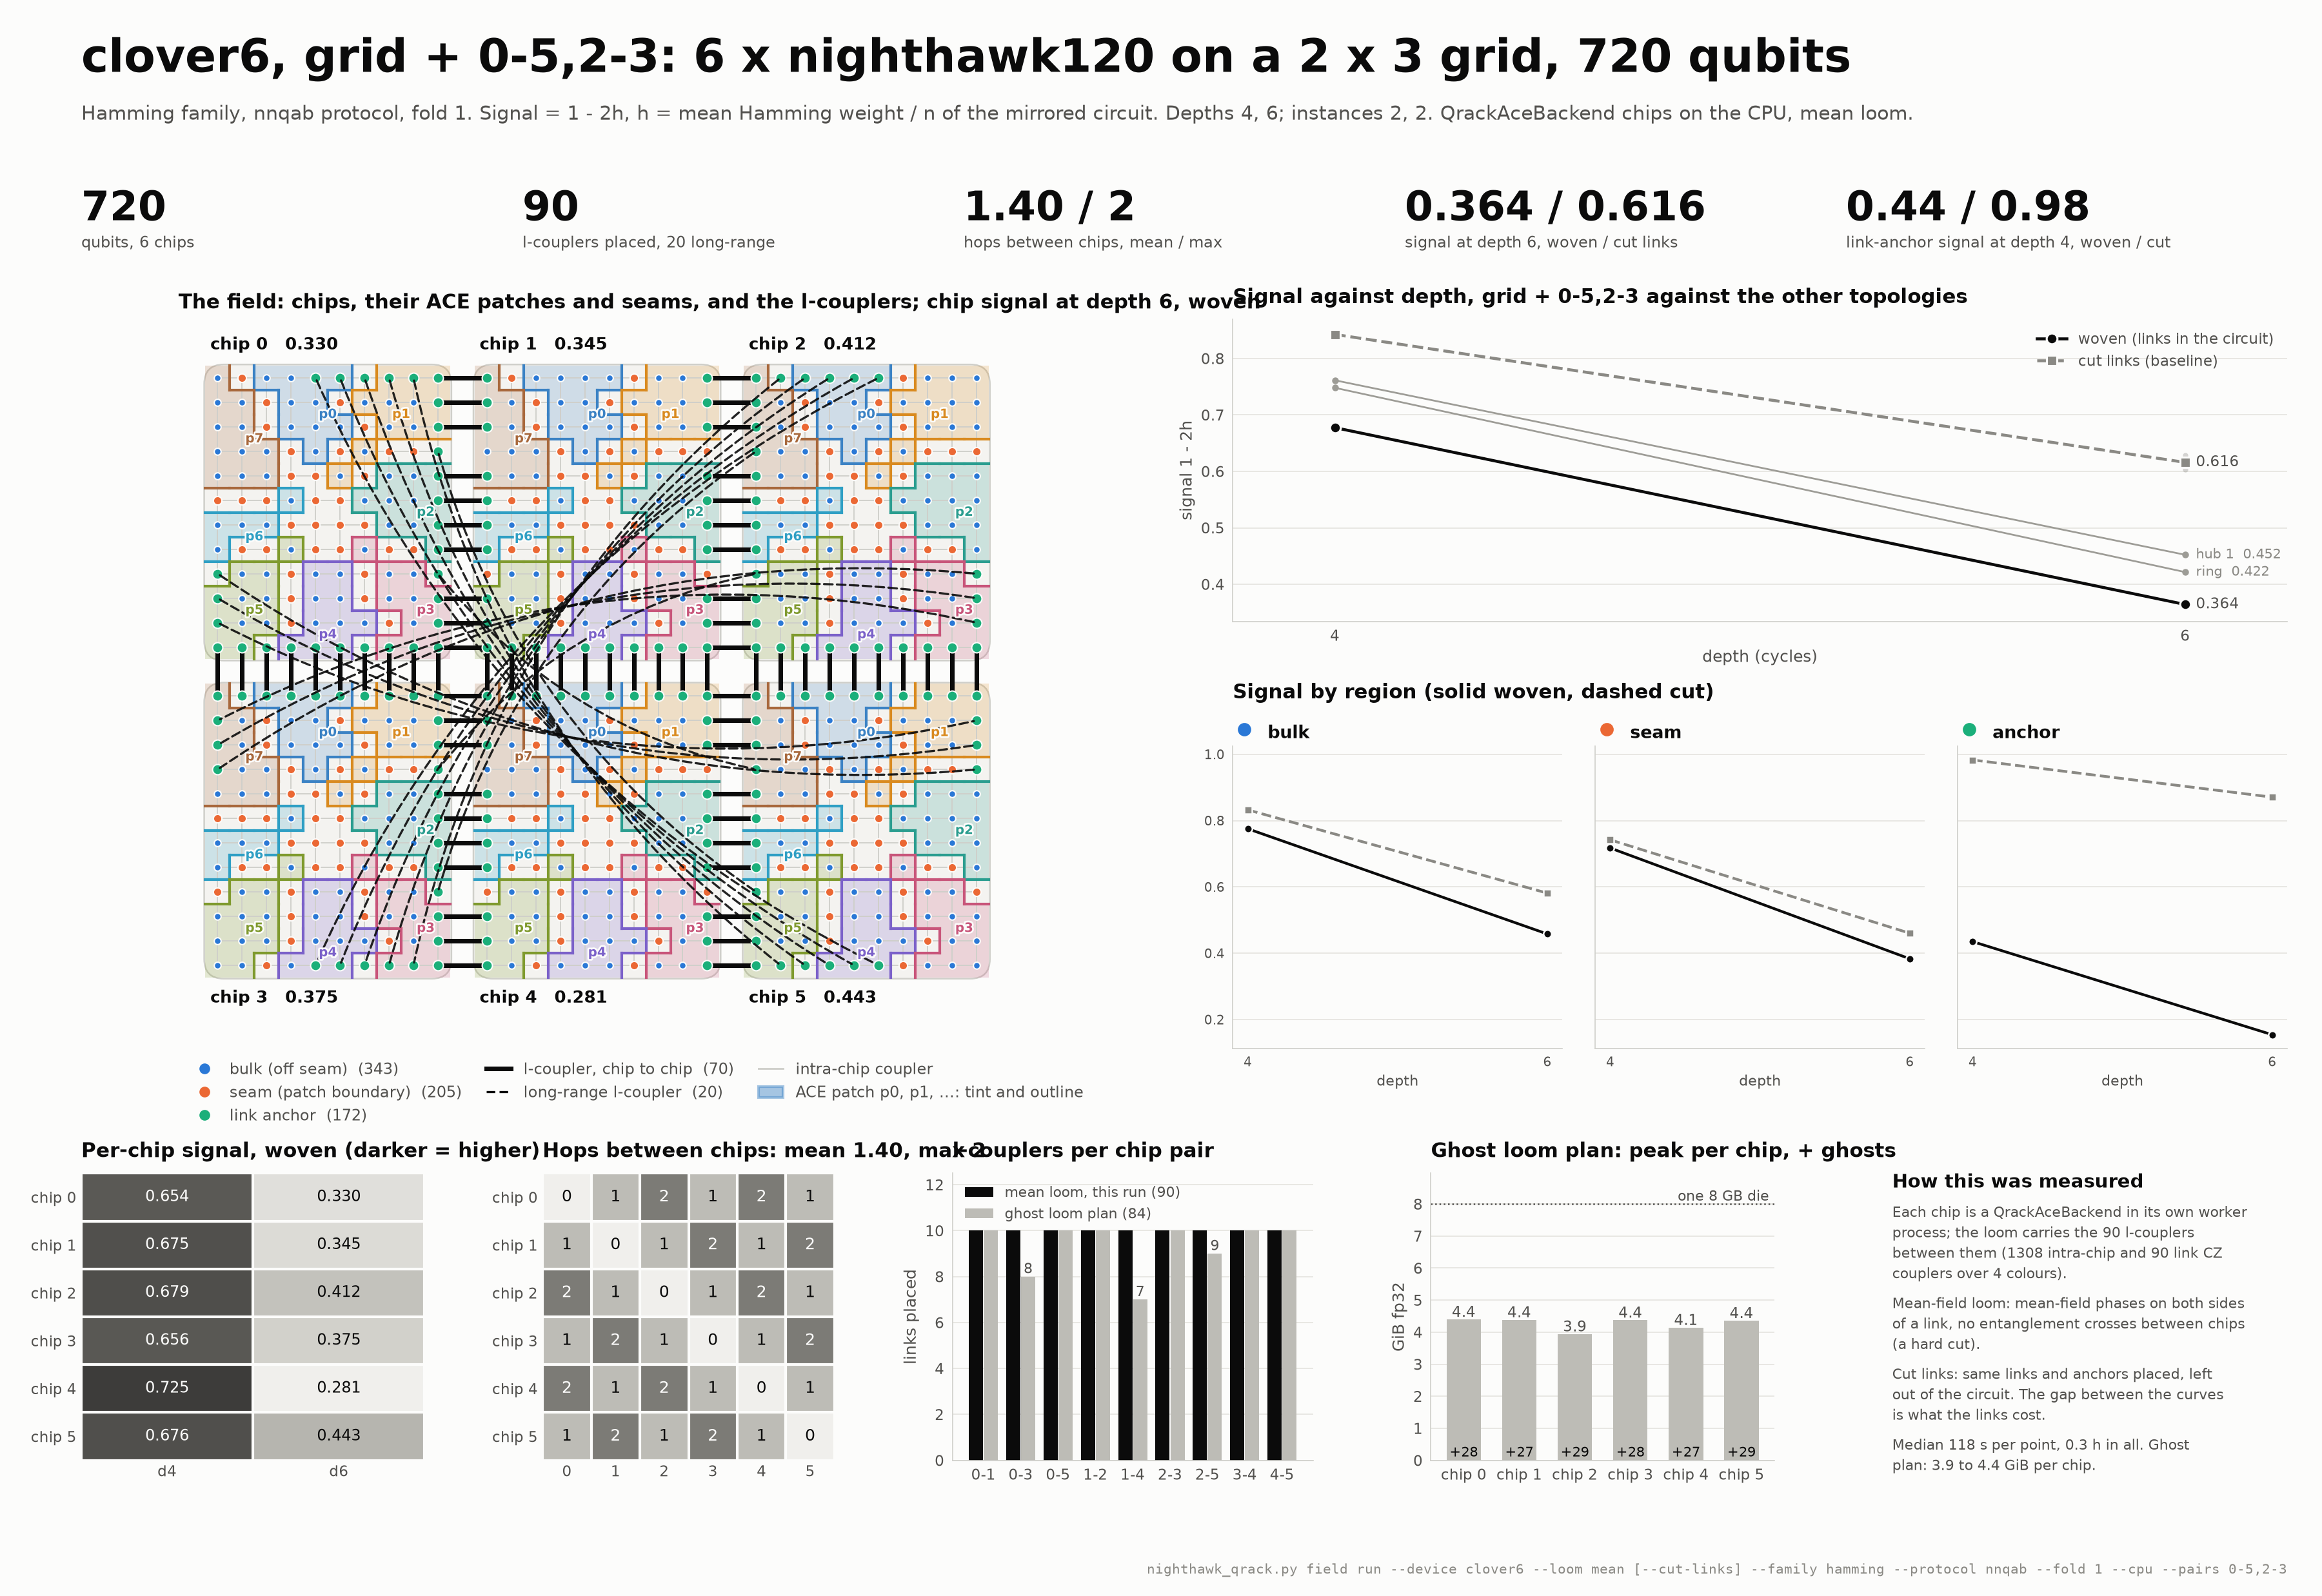

In [8]:
from pathlib import Path
from IPython.display import Image, display

Path("plots_r3").mkdir(exist_ok=True)

!python3 nighthawk_graph.py --out r3_topo.jsonl --table plots_r3/r3_topo.csv
!python3 nighthawk_graph.py --out r3_topo.jsonl --save plots_r3 --figs 12,13,29
!python3 nighthawk_graph.py --out r3_topo.jsonl --poster plots_r3/r3_topo_ring.png --poster-topology ring
!python3 nighthawk_graph.py --out r3_topo.jsonl --poster plots_r3/r3_topo_hub1.png --poster-topology "hub 1"
!python3 nighthawk_graph.py --out r3_topo.jsonl --poster plots_r3/r3_topo_grid_shortcuts.png --poster-topology "grid + 0-5,2-3"

for img_name in [
    "29_fld.png",
    "r3_topo_ring.png",
    "r3_topo_hub1.png",
    "r3_topo_grid_shortcuts.png",
]:
    p = Path("plots_r3") / img_name
    if p.is_file():
        display(Image(filename=str(p)))

### 6.2 Measured RCS, Mirror, Forward XEB, and Hamming Sweeps (`nighthawk.tar.gz`)

Extract the measured sweep archive (`../nighthawk/rcs-nighthawk/nighthawk.tar.gz`, 36 record files / 949 points across 24 configurations) and run `nighthawk_graph.py` to generate the comparison table and views 1–13.

harvesting 36 record files: big_ace.jsonl, big_tile.jsonl, big_var.jsonl, clean_ace.jsonl, clean_ace_c4r7.jsonl, clean_ace_c7r4.jsonl, clean_ace_seam5.jsonl, clean_ace_seam6.jsonl, clean_ace_seam7.jsonl, clvk_t1.jsonl, dan_hamming_36.jsonl, dan_hamming_40.jsonl, dan_hamming_45.jsonl, dan_hamming_49.jsonl, dan_hamming_53.jsonl, dan_hamming_57.jsonl, dan_hamming_61.jsonl, lay_1_7.jsonl, lay_2_2.jsonl, lay_2_7.jsonl, lay_4_3.jsonl, lay_4_4.jsonl, mirror61_dan_d16.jsonl, mirror61_dan_nnqab_cpu.jsonl, mirror61_dan_prob_clvk.jsonl, mirror61_dan_prob_cpu.jsonl, mirror61_dan_prob_pocl.jsonl, mirror61r2_haar.jsonl, pocl_d8_cap.jsonl, pocl_d8_debug.jsonl, repro_d12_cpu.jsonl, tile_1_7.jsonl, tile_2_2.jsonl, tile_2_7.jsonl, tile_4_3.jsonl, tile_4_4.jsonl
ace-01b20966: 149 points, ace-065b88fb: 7 points, ace-0787b67f: 6 points, ace-11fe9332: 31 points, ace-2427ecf0: 1 points, ace-3189ad58: 9 points, ace-37b7c7a6: 1 points, ace-3dcac9f2: 135 points, ace-496fd4a9: 6 points, ace-4b19e847: 20 points, 

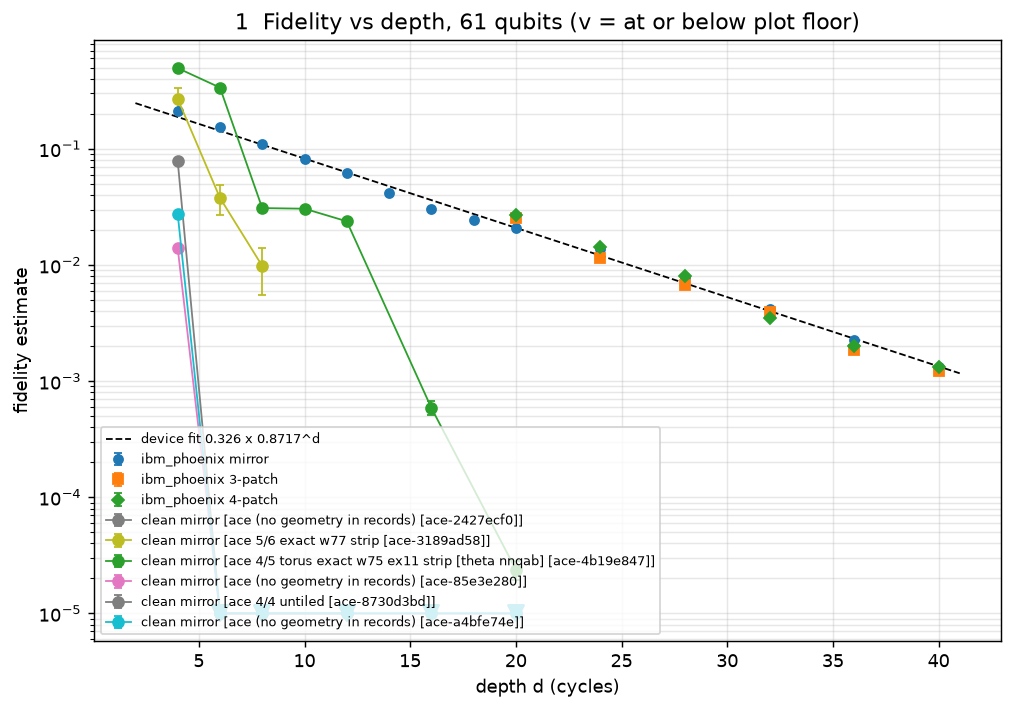

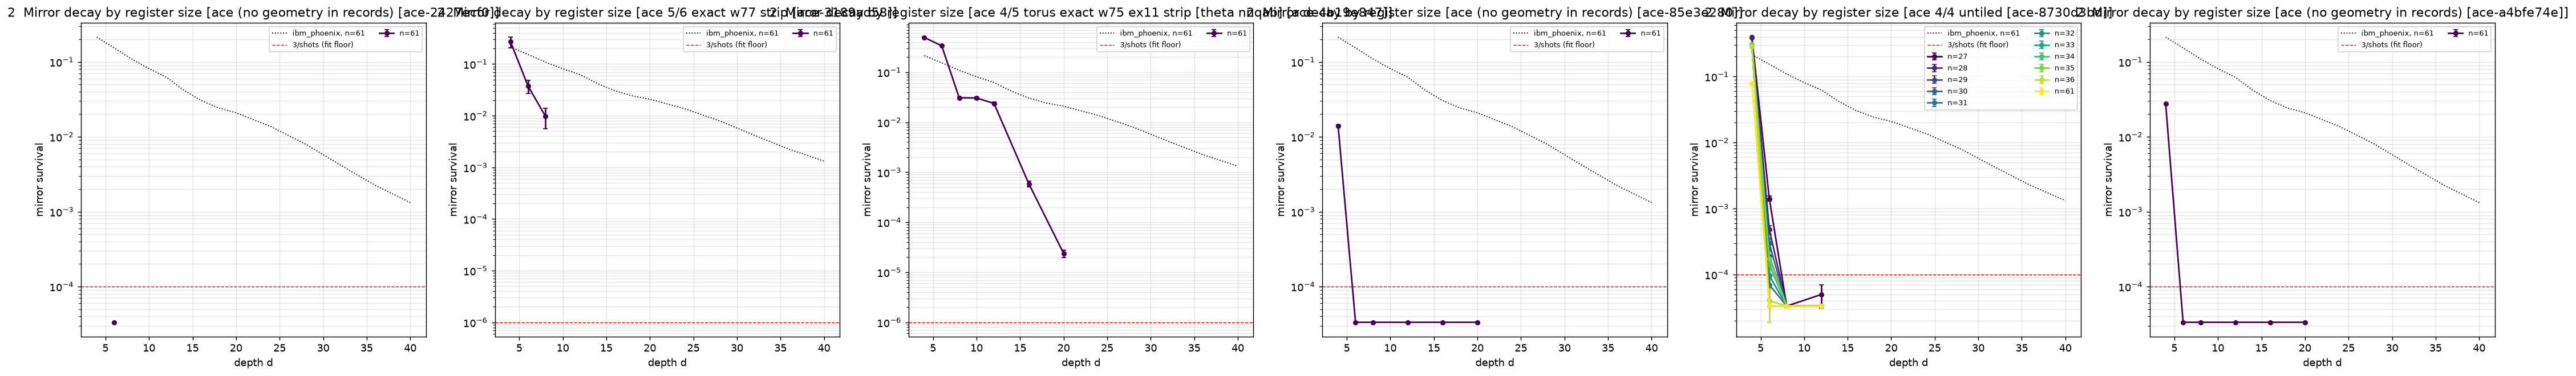

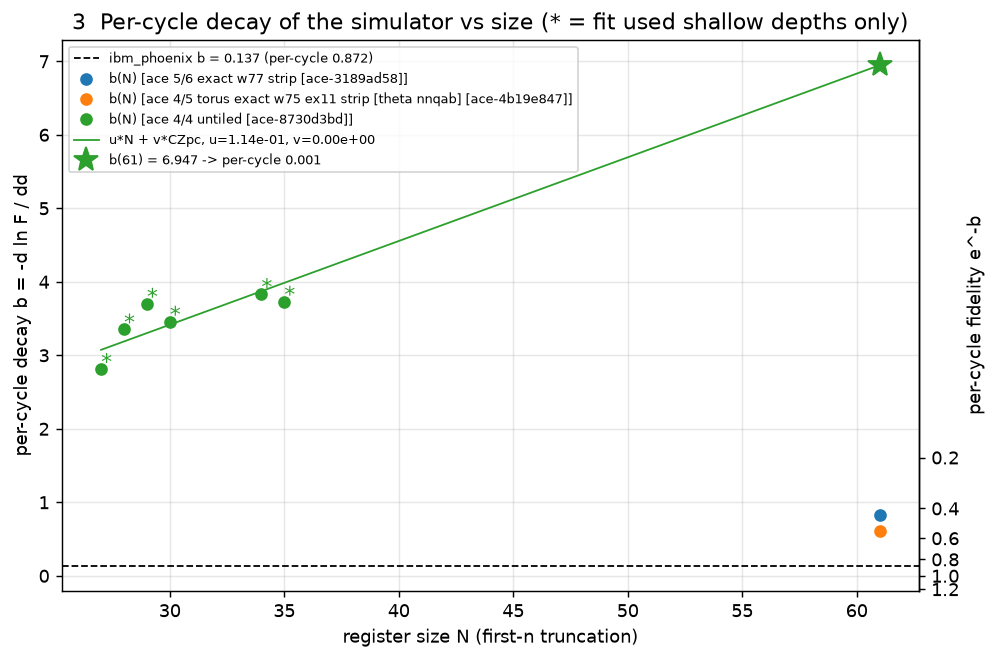

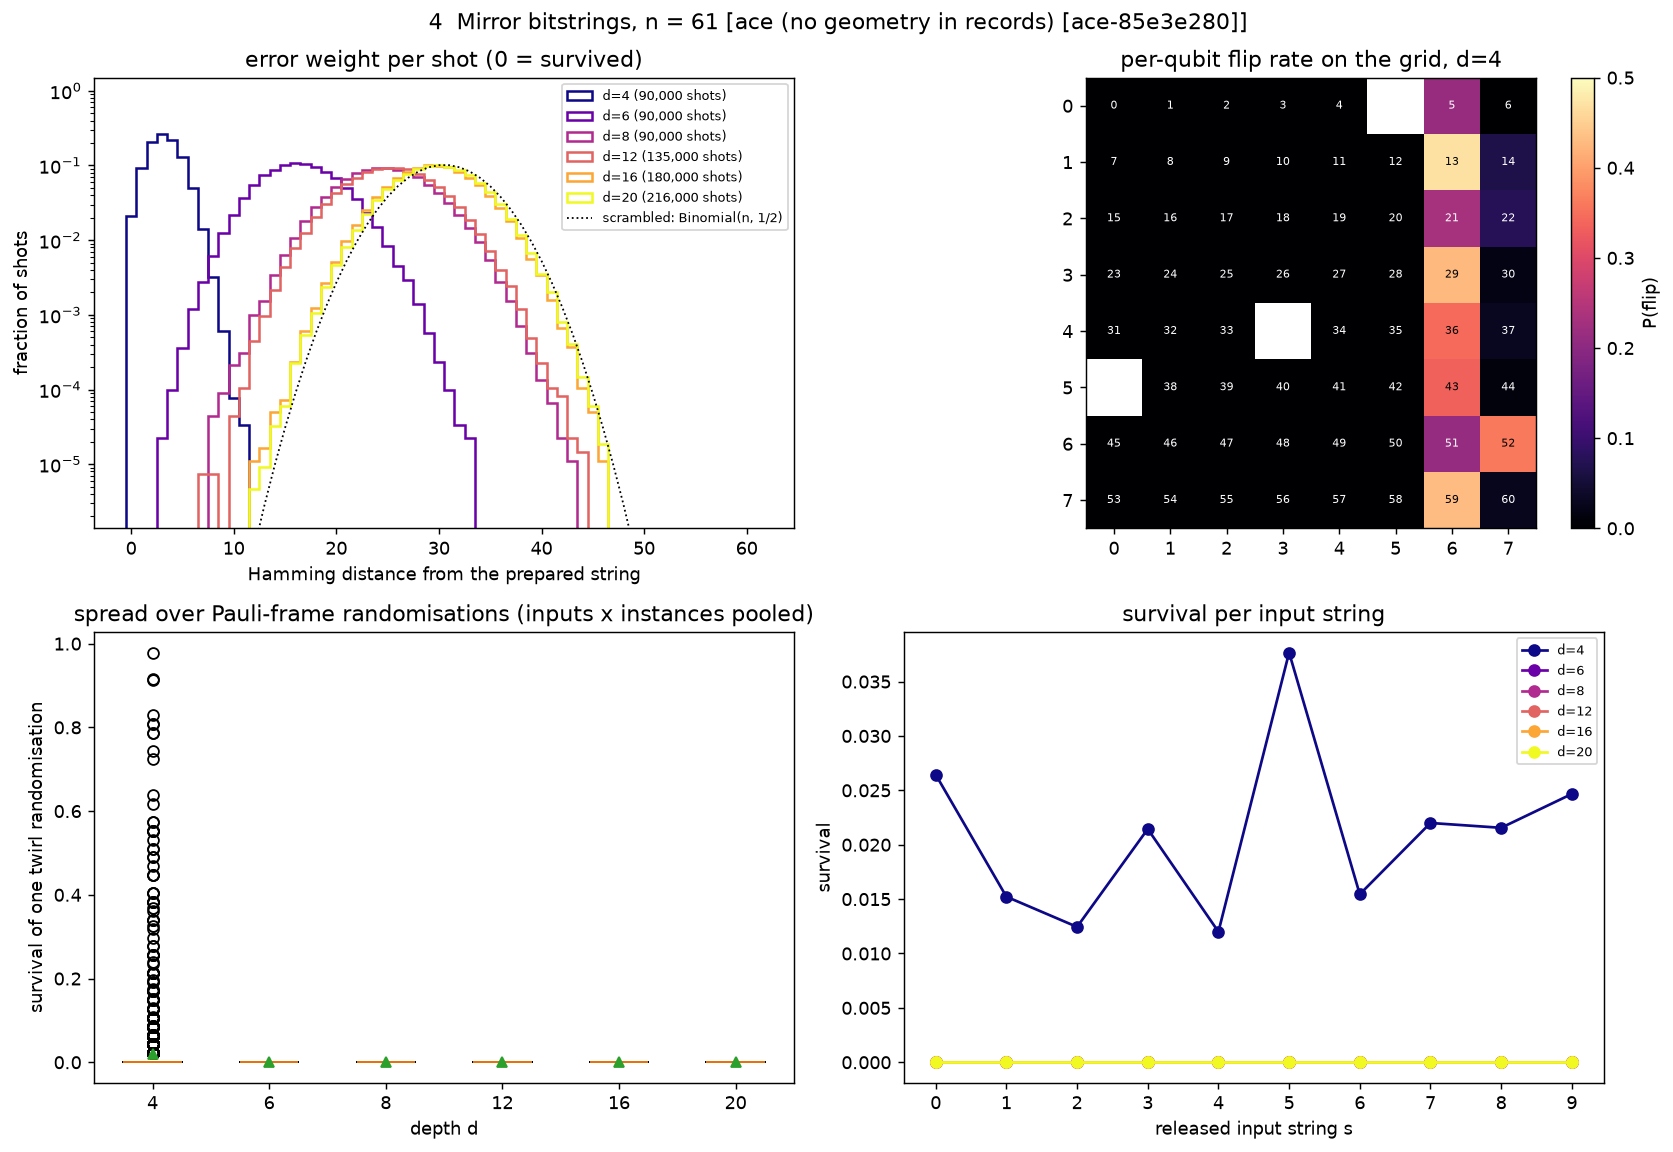

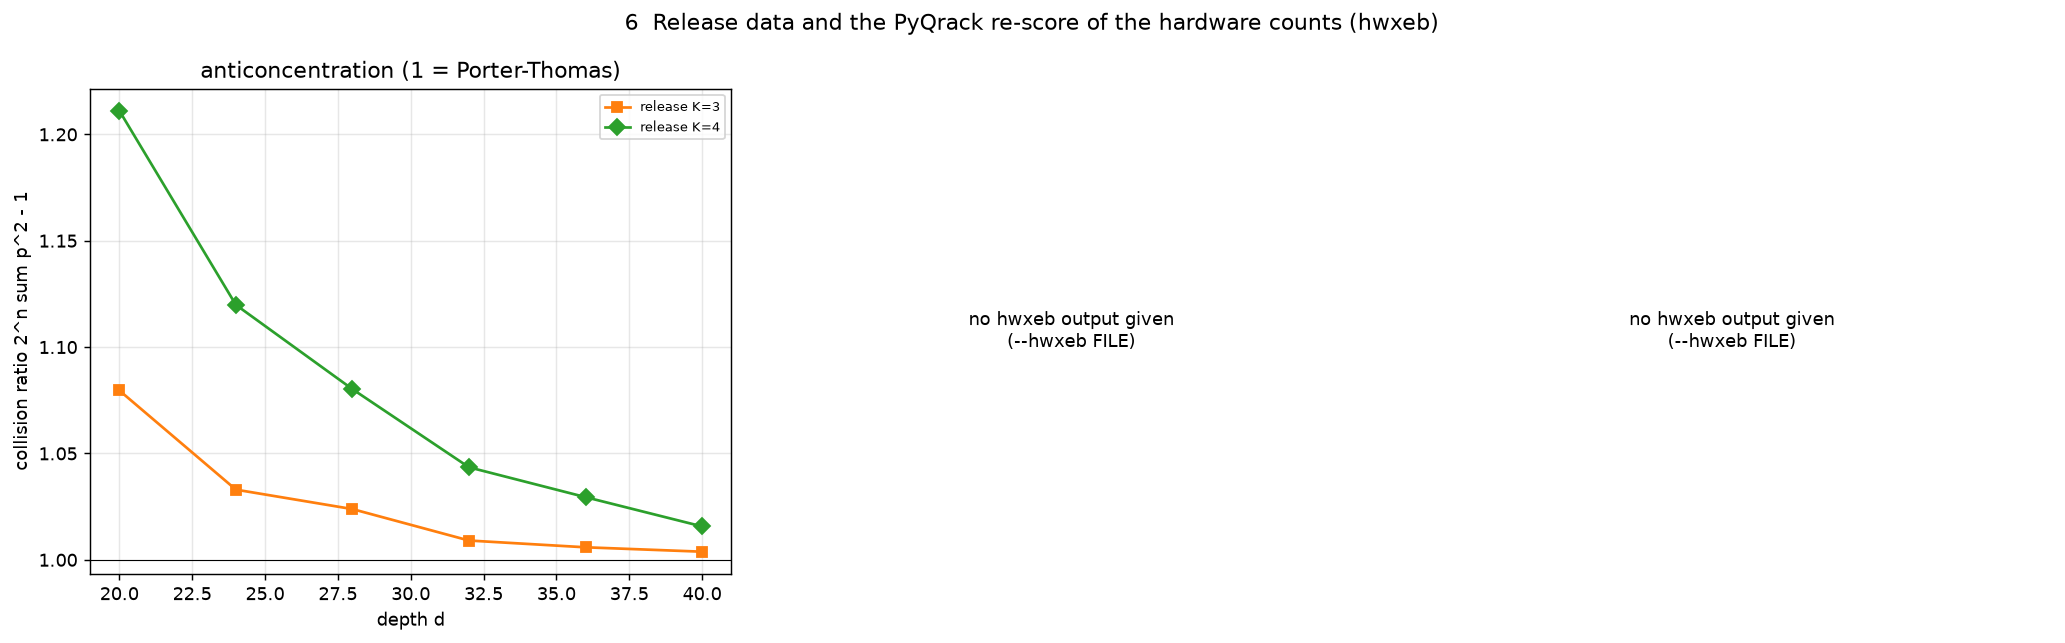

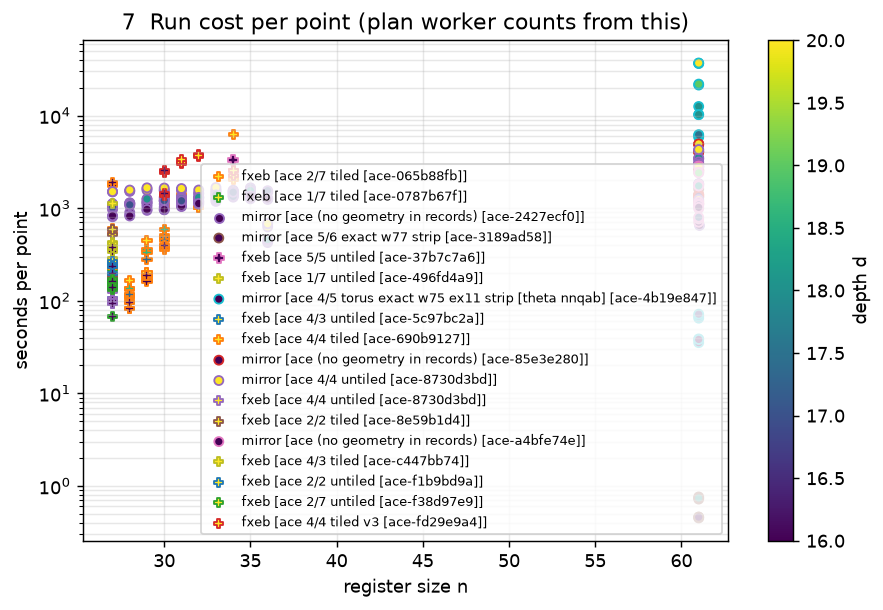

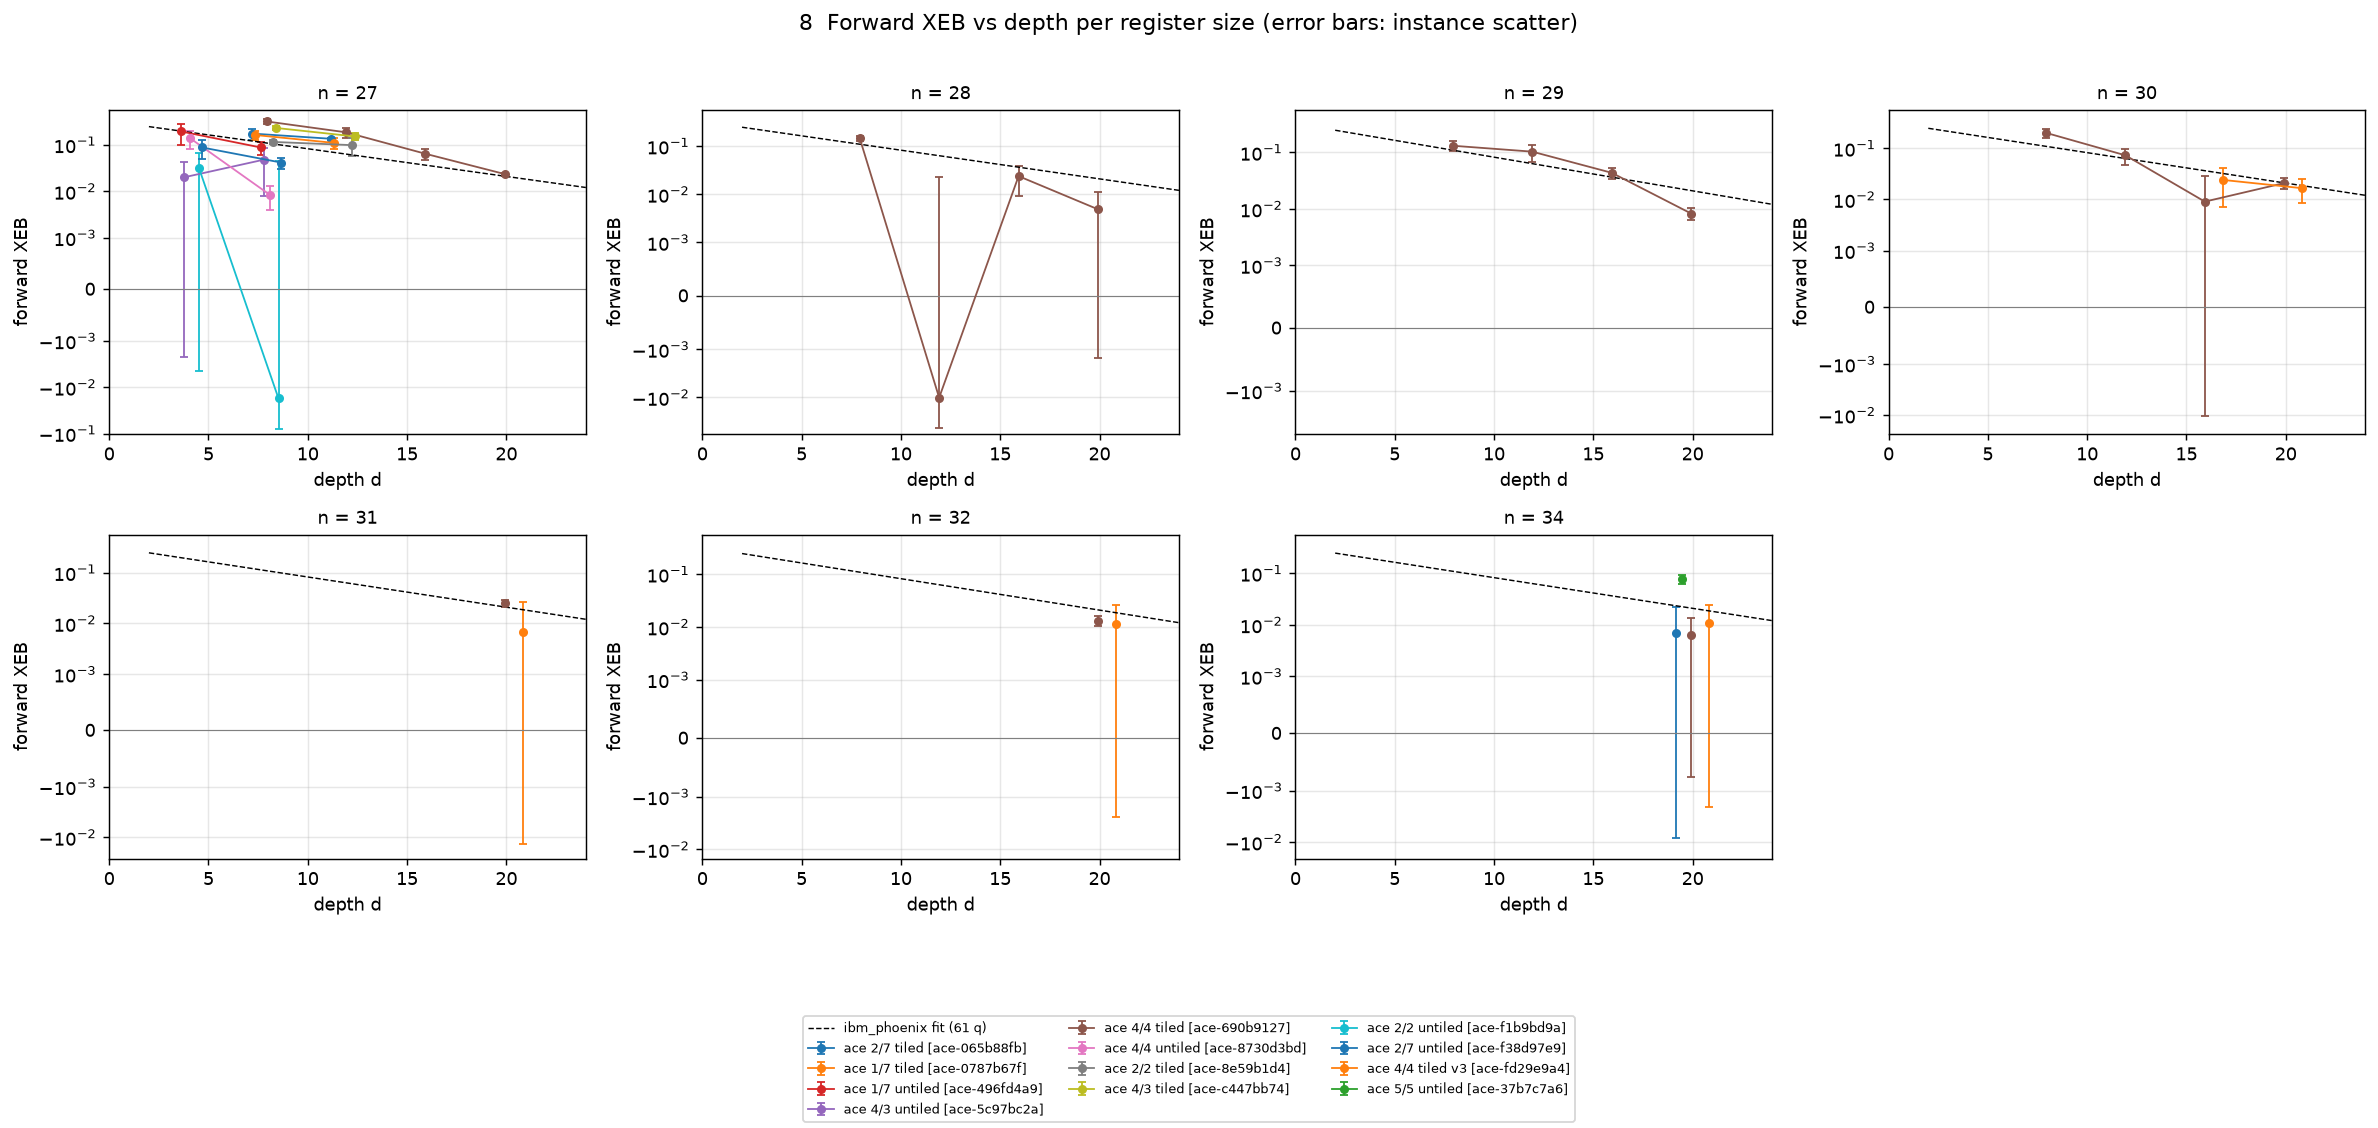

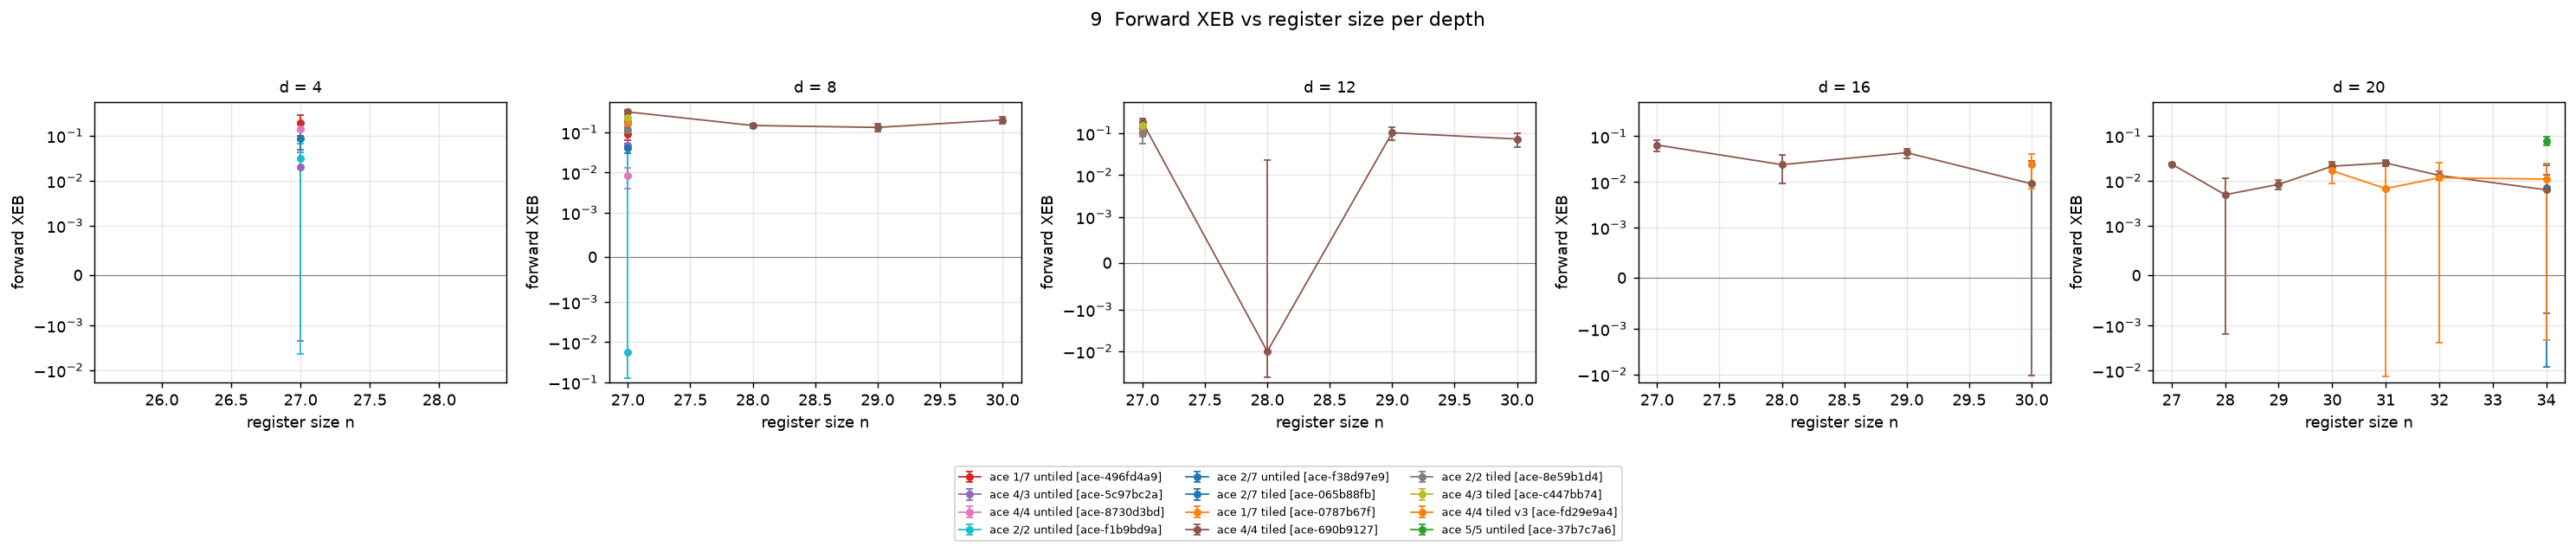

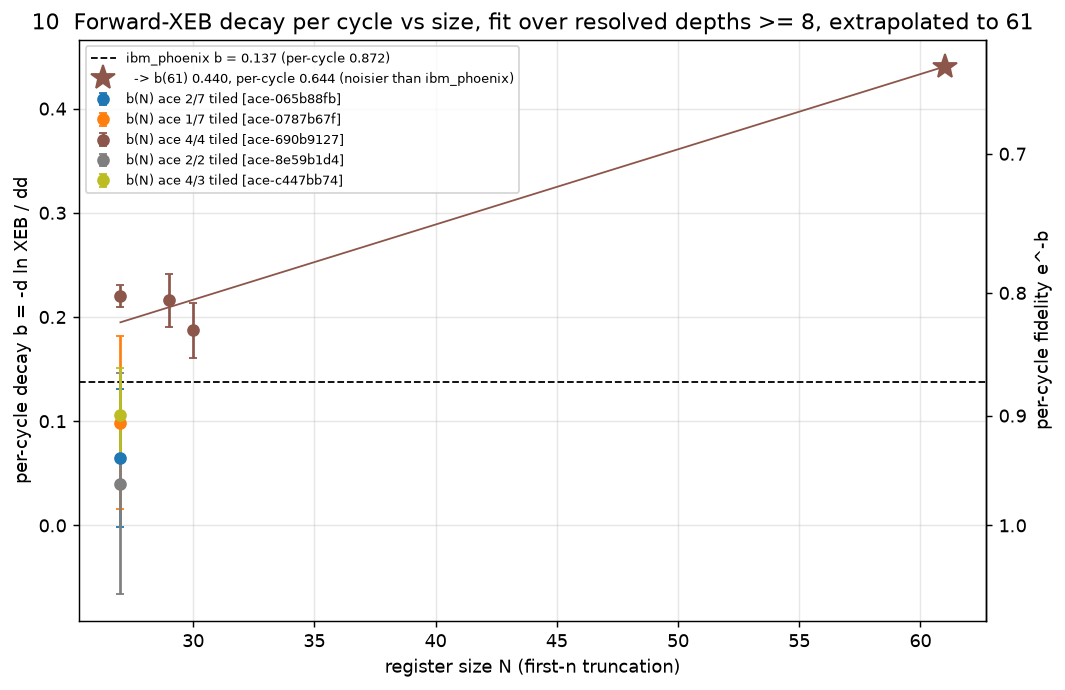

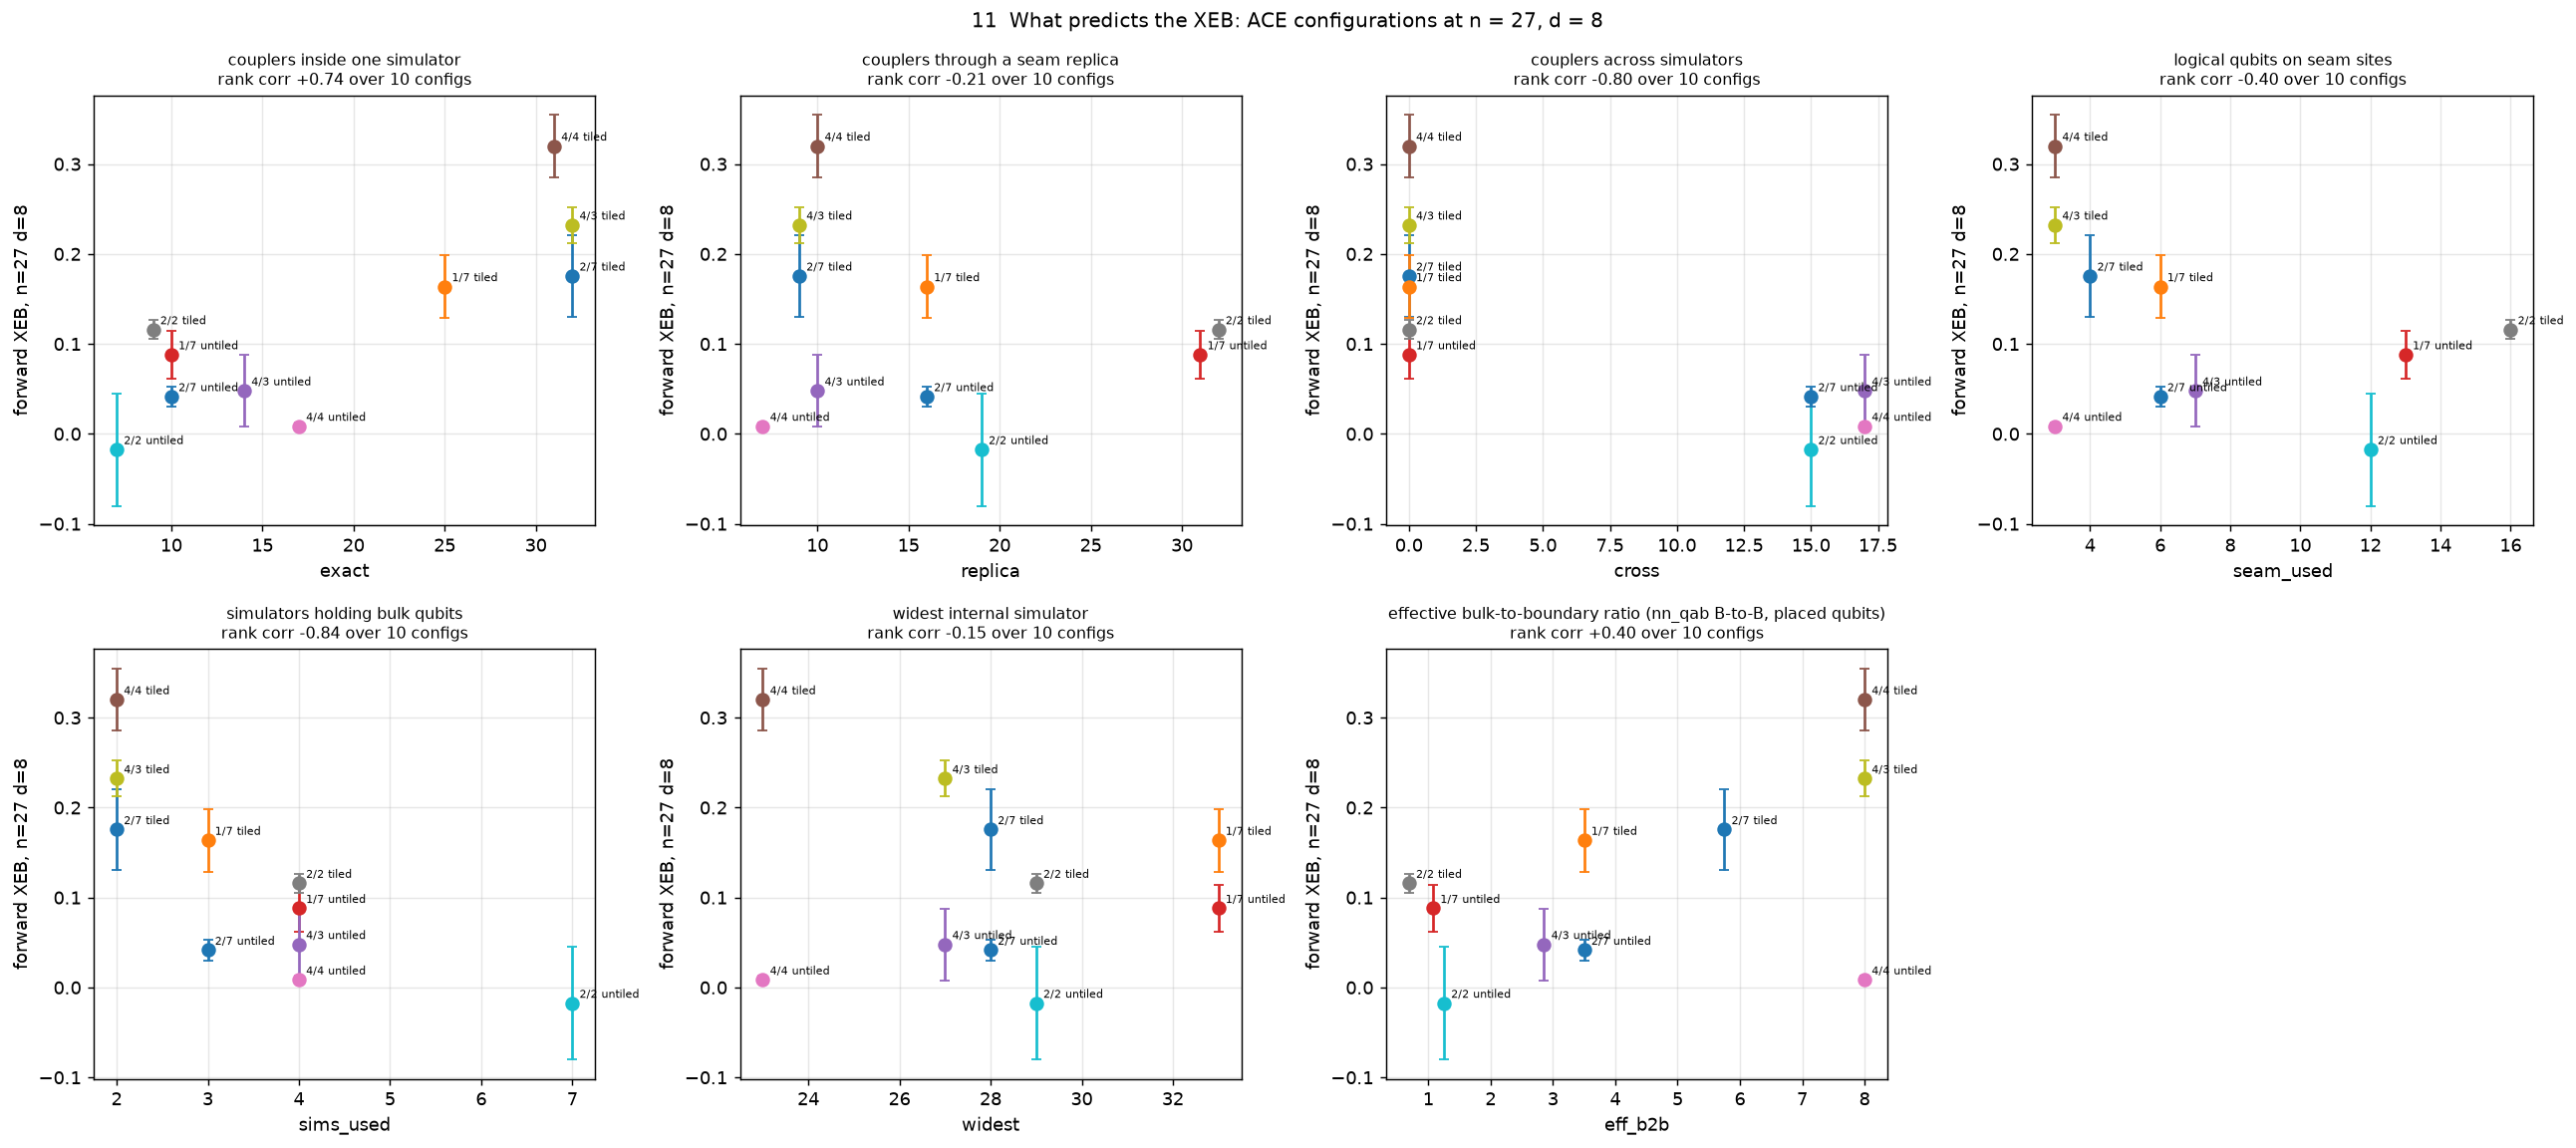

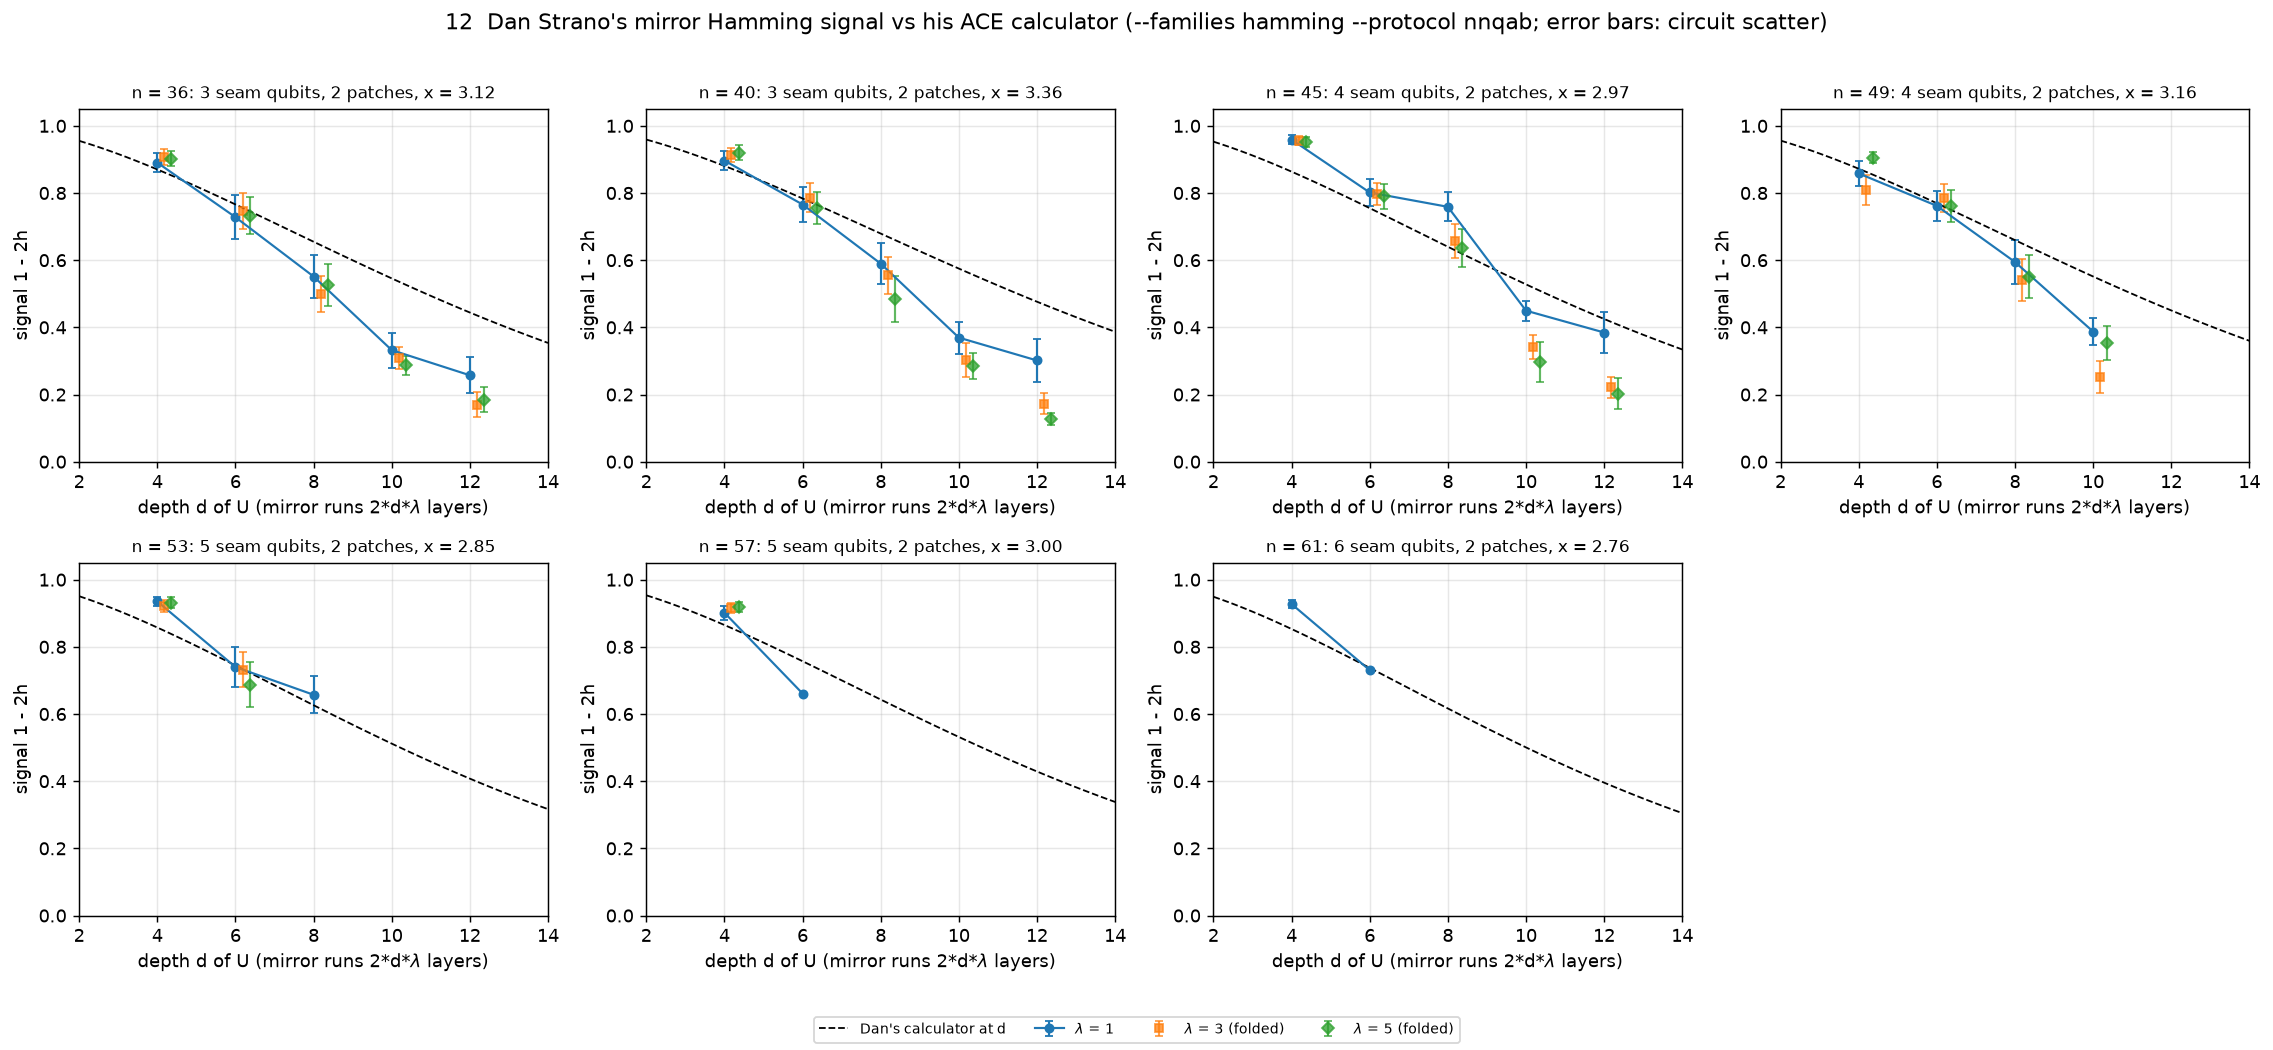

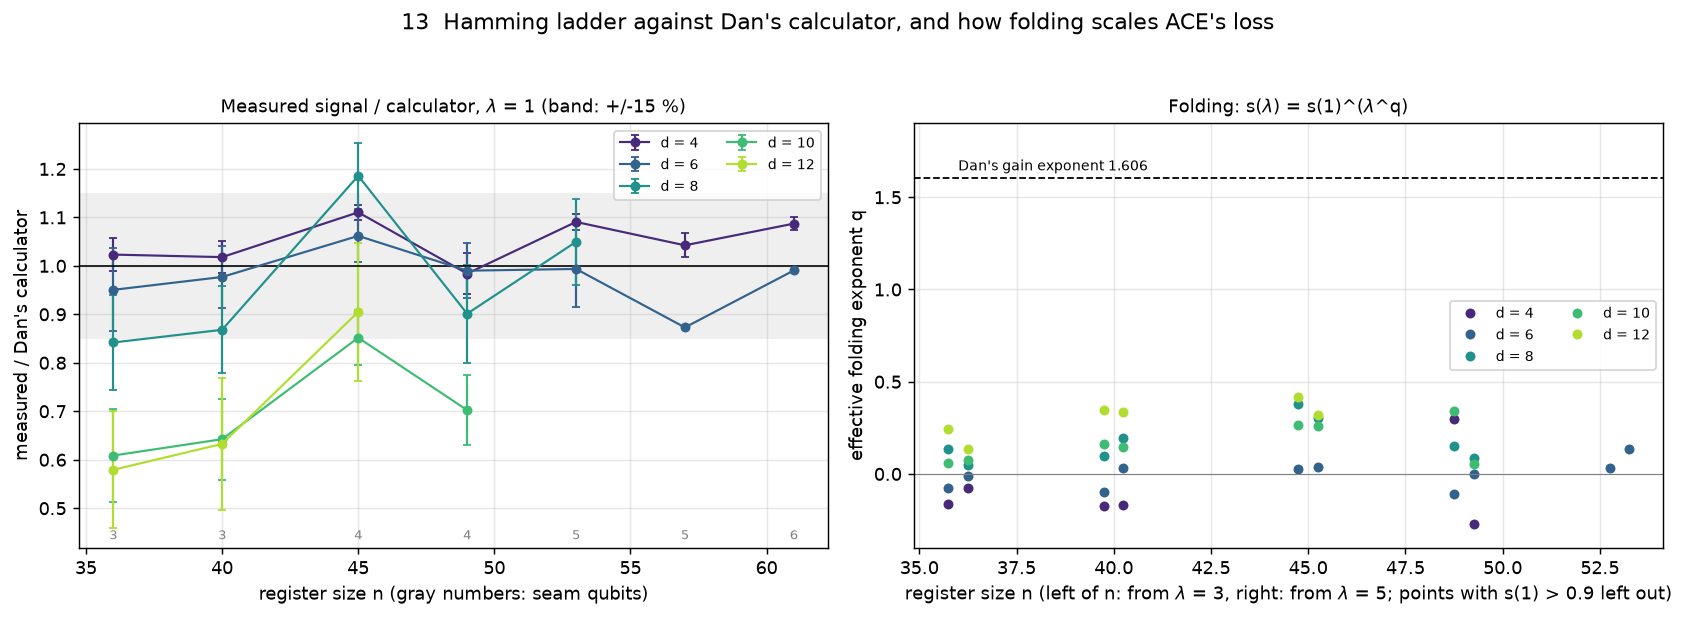

In [9]:
import subprocess
import tarfile
from pathlib import Path
from IPython.display import Image, display

tar_path = Path("../nighthawk/rcs-nighthawk/nighthawk.tar.gz").resolve()
extract_dir = Path("measured_runs")
plots_dir = Path("plots_measured").resolve()
plots_dir.mkdir(exist_ok=True)

if not (extract_dir / "nighthawk").is_dir():
    extract_dir.mkdir(exist_ok=True)
    with tarfile.open(tar_path, "r:gz") as tf:
        tf.extractall(extract_dir)

graph_py = Path("nighthawk_graph.py").resolve()
run_cwd = extract_dir / "nighthawk"

subprocess.run(["python3", str(graph_py), "--table", str(plots_dir / "harvest.csv")], cwd=run_cwd, check=True)
subprocess.run(["python3", str(graph_py), "--save", str(plots_dir)], cwd=run_cwd, check=True)

for img_path in sorted(plots_dir.glob("*.png"), key=lambda p: int(p.name.split("_")[0])):
    print(f"\n=== {img_path.name} ===")
    display(Image(filename=str(img_path)))